# Fase III — Asistente CTI con retrieval entrenado

**Autor:** David Martínez  
**Diplomado en Machine Learning — Universidad Nacional de Colombia — 2026-II**  
**Módulo 6.** El EDA y el hardening ya están en la Fase II. Este notebook entrena el retrieval y deja el asistente en español anclado al índice.

El índice, el entrenamiento y las citas salen solo de `cve_data_hardened.parquet` y `mitre_attack_hardened.parquet`. Si `*_clean` y `*_hardened` vuelven a quedar iguales (E18), la primera celda de código se detiene.

## Cómo leer este notebook

Cada bloque es una celda de código y, debajo, la lectura del resultado. Las barras de época no forman parte de la lectura: abajo quedan el número que decide y la figura.

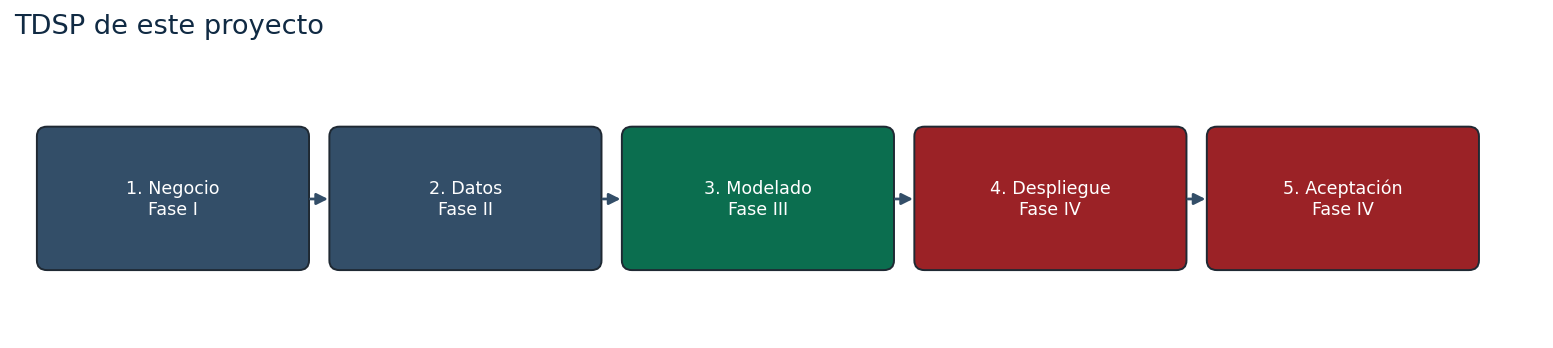

*La Fase III es el modelado. La Fase IV es desplegar este asistente y cerrar la aceptación.*


## Trazabilidad de la rúbrica

La fase pide dos cosas: un diseño experimental con un modelo de deep learning acorde al problema, y un entrenamiento correcto cuya comparación de hiperparámetros mejore el desempeño. Esta corrida las cubre así.

| Barra | Evidencia en este notebook | Lectura |
|-------|----------------------------|---------|
| Diseño con hipótesis, controles y semilla | Sección de diseño. Semilla 42. Gold fuera de los pares | Cumple |
| Modelo de deep learning acorde al dato | Bi-encoder multilingüe, InfoNCE, coseno. No se predice la severidad de Kaggle | Cumple |
| Entrenamiento correcto | 4 000 pares. Documentos del gold en el entrenamiento: 0 | Cumple |
| Los hiperparámetros cambian el resultado | MRR de dev sin identificador: 0,592 → 0,688 al pasar de `2e-5` / 1 época a `1e-4` / 2 épocas | Cumple |
| El hold-out no elige el modelo | Gold del sistema neuronal elegido en desarrollo: MRR 0,961 y Recall@5 1,000 | Cumple |

La meta heredada de la Fase II era MRR ≥ 0,35 y Recall@5 ≥ 0,50. El sistema entregado queda en 0,961 y 1,000. La tercera época mejora el desarrollo y empeora el encoder en el gold; por eso no se despliega. Ese rechazo también es parte del modelado.


## Diseño experimental

**Hipótesis.** Afinar un bi-encoder multilingüe con InfoNCE sobre el texto endurecido sube el MRR frente a MiniLM congelado y frente al mismo modelo sin afinar, cuando la pregunta no trae el CVE.

**Controles.** Misma semilla 42. El gold y los documentos de desarrollo no entran a los pares. TF-IDF y Doc2Vec se quedan como baseline didáctico de la Fase II. Kaggle no entra al ranking. El boost KEV es una ablación y no reordena el asistente. El re-ranker va congelado.

**Selección.** MRR de desarrollo en consultas sin identificador. El gold no se usa para elegir learning rate, épocas ni umbral.

**Métricas.** MRR y Recall@k con la misma definición que `src/threatintel/retrieval_baseline.py`. La meta heredada del protocolo con identificador es MRR ≥ 0,35 y Recall@5 ≥ 0,50.

**Generación.** Plantilla en español con veredicto, evidencia, acción y límite. Si el identificador nombrado no está en el índice, el asistente se abstiene. No genera exploits.


In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

HERE = Path.cwd().resolve()
ROOT = HERE
for cand in [HERE, *HERE.parents]:
    if (cand / "configs" / "retrieval.yaml").is_file():
        ROOT = cand
        break
sys.path.insert(0, str(ROOT / "src"))

from threatintel.rag.experiment import (
    checklist_score,
    dev_answerable,
    dev_gate_rows,
    fmt_num,
    official_abstain_queries,
    pack_metrics,
    SCENARIO_SPECS,
)
from threatintel.rag.gate import calibrate_threshold
from threatintel.rag.generate import answer_query
from threatintel.rag.run_fase3 import (
    answer_items,
    abstention_summary,
    citation_summary,
    dense_query_details,
    evaluate_bm25,
    frozen_reference,
    hybrid_rankings_for,
    load_encoder,
    metric_line,
    prepare,
    reproduce_fase2,
    save_comparison_figure,
    save_loss_figure,
    train_grid,
    write_experiment_table,
)
from threatintel.rag.retrieve import BM25Index
from threatintel.rag.train import describe_architecture
from threatintel.eval.reports import write_modeling_docs
from threatintel.rag.experiment import dump_json

state = prepare(ROOT)
cfg = state["cfg"]
lineage = state["lineage"]
corpus = state["corpus"]
splits = state["splits"]
print("LINAJE — el entrenamiento no sigue si esta comprobación falla")
print(
    f"CVE clean {lineage['cve_clean_shape']} | hardened {lineage['cve_hard_shape']} | "
    f"MITRE clean {lineage['mitre_clean_shape']} | hardened {lineage['mitre_hard_shape']}"
)
print(
    f"detection nulo: clean {lineage['detection_null_clean']:.0%} | "
    f"hardened {lineage['detection_null_hardened']:.0%}"
)
print(
    f"Unknown likely_mitre_tactic {lineage['unknown_tactic']:.2%} | "
    f"likely_mitre_tactic_enriched {lineage['unknown_enriched']:.2%}"
)
print(f"índice = {lineage['index_source']}")
print(
    f"corpus {len(corpus)} chunks | CVE {(corpus.doc_type == 'cve').sum()} | "
    f"MITRE {(corpus.doc_type == 'mitre').sum()} | padres {corpus.doc_id.nunique()}"
)
print(
    f"pares de entrenamiento {len(splits['train_pairs'])} | dev {len(splits['dev_items'])} | "
    f"paráfrasis {len(splits['paraphrases'])} | gold ampliado {len(splits['gold_f3'])}"
)
print("documentos del gold en los pares:", len(set(splits["train_pairs"].positive_doc_id.astype(str)) & splits["banned_ids"]))


LINAJE — el entrenamiento no sigue si esta comprobación falla
CVE clean [5000, 30] | hardened [5000, 38] | MITRE clean [697, 14] | hardened [697, 22]
detection nulo: clean 100% | hardened 0%
Unknown likely_mitre_tactic 39.54% | likely_mitre_tactic_enriched 16.48%
índice = hardened
corpus 6745 chunks | CVE 5000 | MITRE 1745 | padres 5697
pares de entrenamiento 4000 | dev 85 | paráfrasis 32 | gold ampliado 72
documentos del gold en los pares: 0


### Lectura — linaje

El índice solo sigue si `clean` y `hardened` son archivos distintos. En esta corrida lo son.

- `detection` nulo: 100 % en el limpio y 0 % en el endurecido.
- Unknown en `likely_mitre_tactic`: 39,54 %. En la columna enriquecida: 16,48 %. La primera no está “ya corregida”.
- Corpus: 6 745 chunks, 5 697 documentos padre. Pares de entrenamiento: 4 000. Documentos del gold dentro de esos pares: 0.


In [2]:
base = load_encoder(cfg["models"]["biencoder"], int(cfg["max_seq_length"]))
print(describe_architecture(base))
print("pérdida de entrenamiento: MultipleNegativesRankingLoss scale=20")
del base


C:\Users\J2KUSER\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Bi-encoder siamés: la misma torre codifica la consulta y el documento.
Similitud: coseno de embeddings L2-normalizados.
Pérdida: MultipleNegativesRankingLoss (InfoNCE) con scale=20 (temperatura 0.05).
Negativos: el resto del lote; no hay negativos etiquetados a mano.
El texto indexado sale de los parquets hardened: táctica enriquecida y detection STIX.
Módulos:
- 0: Transformer
- 1: Pooling
Transformer: BertConfig, capas=12, hidden=384, atención=12.
Pooling: mean.
max_seq_length=256.
pérdida de entrenamiento: MultipleNegativesRankingLoss scale=20


### Lectura — arquitectura

La red es un BERT de 12 capas, hidden 384 y pooling medio. La misma torre codifica la pregunta y el documento. La pérdida es InfoNCE con escala 20: en un lote de 32, cada pregunta tiene 31 negativos. No se entrena un modelo que escriba texto libre ni uno que prediga la severidad de Kaggle.


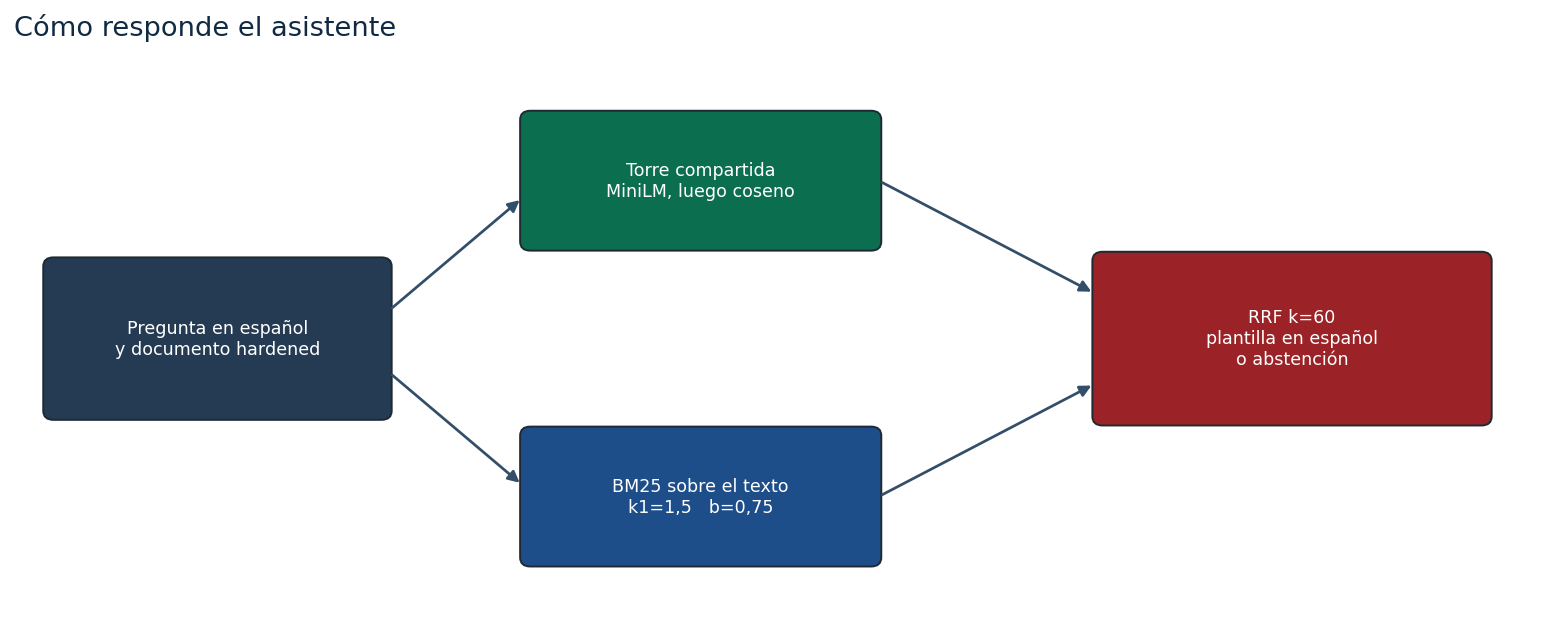

*La pregunta y el documento comparten la torre siamesa (M5U5) del encoder Transformer (M5U4). BM25 y el coseno se fusionan antes de la plantilla en español.*


In [ ]:
from pathlib import Path
# CURSO-A-COMPONENTE
print('Mapa curso → componente')
print('M4U2  preparación del corpus     → hardening + lineage_gate')
print('M4U3  embeddings clásicos        → TF-IDF / BM25 baseline')
print('M4U4  train / val / test         → pares, grilla, gold')
print('M4U5  similitud semántica        → coseno + MRR / Recall@k')
print('M5U1  fine-tuning DL             → train_biencoder')
print('M5U4  encoder Transformer        → MiniLM 12 capas')
print('M5U5  red siamesa + contrastive  → bi-encoder InfoNCE')
print('Entrega / Fase IV                → biencoder_best + RRF')
print('Fuera de alcance                 → CNN (M5U3), generativos imagen')


Mapa curso → componente
M4U2  preparación del corpus     → hardening + lineage_gate
M4U3  embeddings clásicos        → TF-IDF / BM25 baseline
M4U4  train / val / test         → pares, grilla, gold
M4U5  similitud semántica        → coseno + MRR / Recall@k
M5U1  fine-tuning DL             → train_biencoder
M5U4  encoder Transformer        → MiniLM 12 capas
M5U5  red siamesa + contrastive  → bi-encoder InfoNCE
Entrega / Fase IV                → biencoder_best + RRF
Fuera de alcance                 → CNN (M5U3), generativos imagen


### Lectura — del curso al modelo de la entrega

El bi-encoder es la **red siamesa** del Módulo 5 (pares ancla–positivo, pérdida contrastiva / InfoNCE) sobre un **encoder Transformer** (MiniLM, autoatención). El Módulo 4 aporta el ciclo train/val/test, los embeddings clásicos como baseline y la similitud semántica como métrica de ranking.

CNN y los generativos de imagen del mismo módulo no entran al asistente SOC. Detalle página a página: `docs/knowledge/base_curso_m4_m5.md`. Matriz de rúbrica: `Fase_III/12_evidencia_rubrica_fase3.md`.

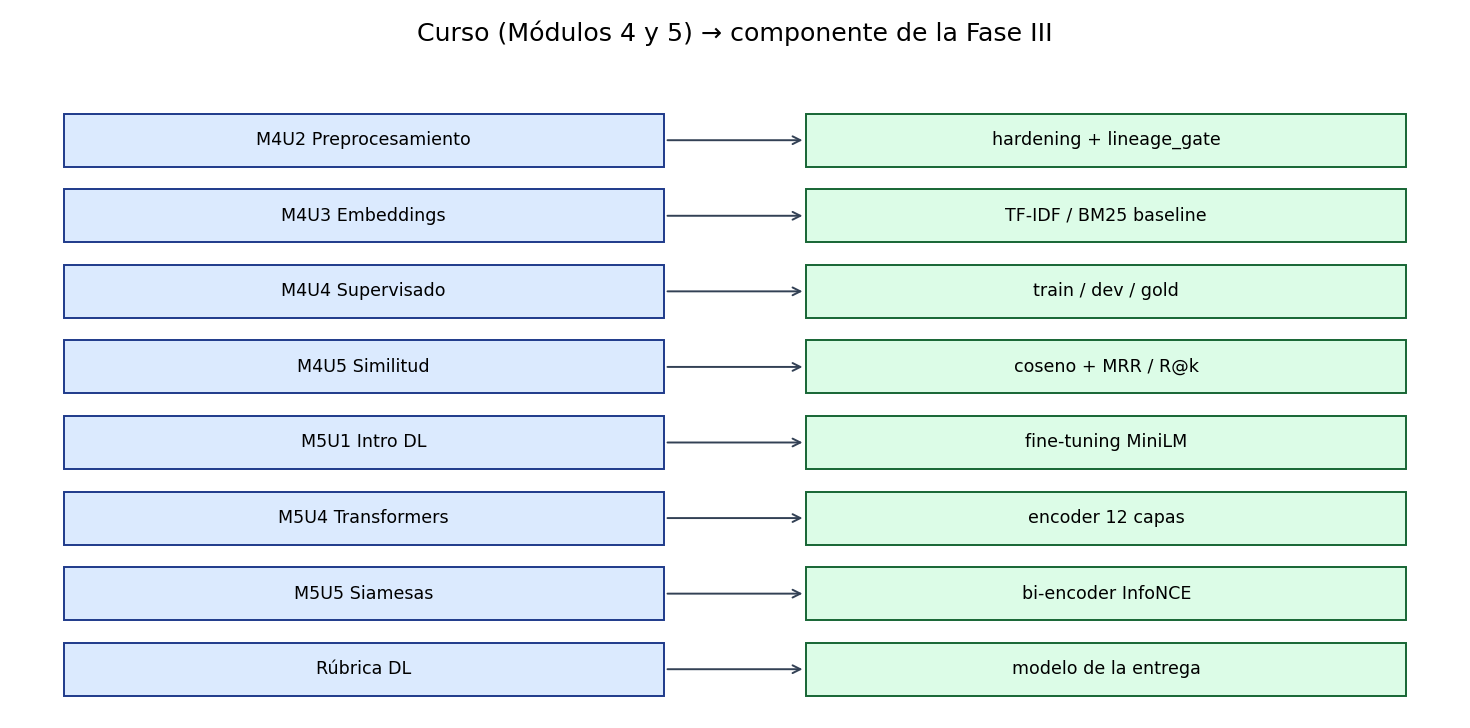

*Curso (Módulos 4 y 5) → componente de la Fase III.*


In [3]:
dev_items = state["splits"]["dev_items"]
dev_rank = dev_answerable(dev_items)
print(f"consultas de dev con documento relevante: {len(dev_rank)}")
minilm_dev, _minilm_emb = frozen_reference(state, cfg["models"]["baseline_minilm"], dev_rank)
del _minilm_emb
bm25_dev = evaluate_bm25(corpus, dev_rank, "bm25")
multi_dev, multi_emb = frozen_reference(state, cfg["models"]["biencoder"], dev_rank)
for label, packed in [("MiniLM", minilm_dev), ("BM25", bm25_dev), ("multilingüe congelado", multi_dev)]:
    print(
        f"{label:24} MRR {fmt_num(packed['all']['mrr'])} | "
        f"sin id {fmt_num(packed['without_id']['mrr'])} | "
        f"R@5 sin id {fmt_num(packed['without_id']['recall_at_k']['5'])}"
    )


consultas de dev con documento relevante: 60


MiniLM                   MRR 0.476 | sin id 0.654 | R@5 sin id 0.700
BM25                     MRR 0.597 | sin id 0.749 | R@5 sin id 0.767
multilingüe congelado    MRR 0.397 | sin id 0.557 | R@5 sin id 0.633


### Lectura — controles de desarrollo

Estos números son de desarrollo, no del gold. El multilingüe congelado, que es el punto de partida del afinado, queda en MRR 0,557 sin identificador. MiniLM, en inglés, queda en 0,654. BM25, que aprovecha el texto, queda en 0,749. La grilla tiene que superar al multilingüe congelado para que el encoder afinado se despliegue.


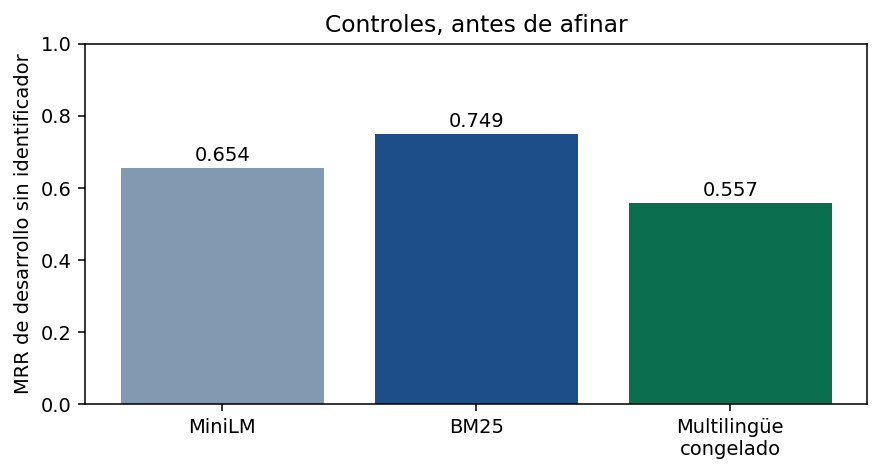

*MRR de desarrollo sin identificador, antes de entrenar.*


In [4]:
grid = train_grid(state)
print("grilla (selección = MRR de dev sin identificador)")
for row in grid["rows"]:
    print(
        f"{row['tag']:14} loss {fmt_num(row['train_loss_last'])} | "
        f"MRR sin id {fmt_num(row['dev_mrr_without_id'])} | "
        f"R@5 sin id {fmt_num(row['dev_r5_without_id'])}"
    )
fig_dir = ROOT / cfg["paths"]["figures"]
save_loss_figure(grid["curves"], fig_dir / "fase3_hp_loss.png")
print("figura:", fig_dir / "fase3_hp_loss.png")


Entrenando lr2e-05_ep1 sobre 4000 pares del índice hardened…


Step,Training Loss
10,1.050430
20,0.923206
30,0.672251
40,0.525744
50,0.313732
60,0.198222
70,0.139833
80,0.145721
90,0.141617
100,0.188815


dev MRR sin id=0.592 R@5 sin id=0.733 loss=0.102


Entrenando lr2e-05_ep2 sobre 4000 pares del índice hardened…


Step,Training Loss
10,1.090405
20,0.973841
30,0.735898
40,0.643616
50,0.365949
60,0.215861
70,0.146036
80,0.131988
90,0.124634
100,0.153627


dev MRR sin id=0.632 R@5 sin id=0.733 loss=0.037


... (4 outputs left out)

Step,Training Loss
10,1.007028
20,0.765812
30,0.315174
40,0.201462
50,0.107399
60,0.102658
70,0.039256
80,0.054155
90,0.052402
100,0.062082


dev MRR sin id=0.688 R@5 sin id=0.733 loss=0.010


grilla (selección = MRR de dev sin identificador)
lr2e-05_ep1    loss 0.102 | MRR sin id 0.592 | R@5 sin id 0.733
lr2e-05_ep2    loss 0.037 | MRR sin id 0.632 | R@5 sin id 0.733
lr1e-04_ep1    loss 0.060 | MRR sin id 0.652 | R@5 sin id 0.733
lr1e-04_ep2    loss 0.010 | MRR sin id 0.688 | R@5 sin id 0.733


figura: C:\Users\J2KUSER\Documents\Diplomado Machine learning Unal 2026\Módulo 6\Proyecto Fase III\docs\data\figures\fase3_hp_loss.png


### Lectura — grilla

La pérdida baja en las cuatro corridas. No es el criterio de elección. El criterio es el MRR de desarrollo sin identificador, y sube de 0,592 a 0,688. El Recall@5 sin identificador se queda en 0,733: la grilla mejora el puesto del documento correcto, no la cantidad de aciertos dentro de los cinco primeros. Se entrega `lr 1e-4`, 2 épocas.


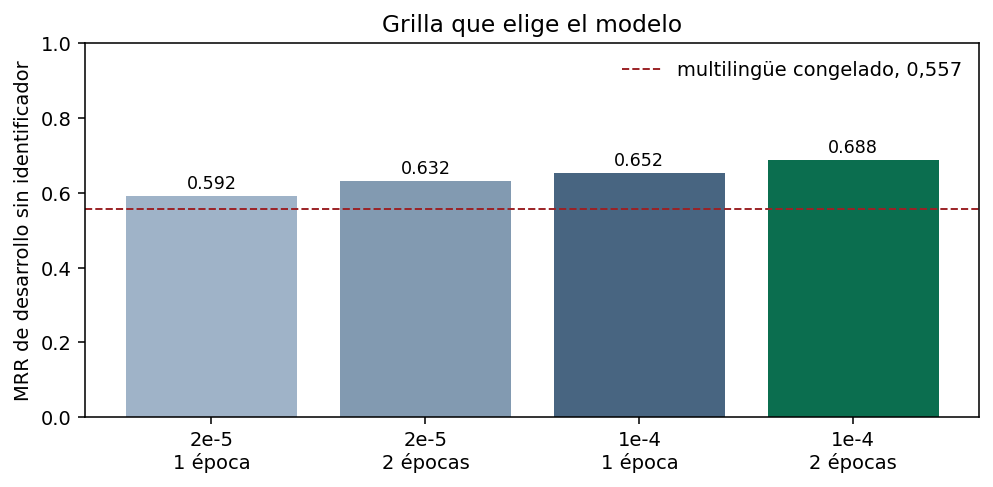

*La barra verde es el checkpoint que se entrega.*


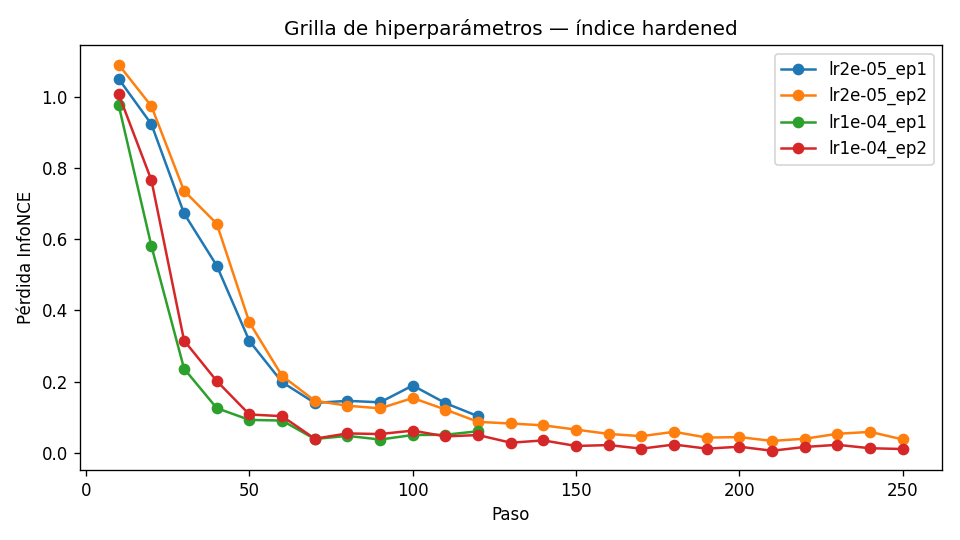

*La pérdida acompaña el entrenamiento. No elige el modelo.*


In [5]:
best = grid["best"]["record"]
frozen_score = multi_dev["without_id"]["mrr"] or -1.0
tuned_score = best["dev_mrr_without_id"] or -1.0
if frozen_score > tuned_score + 1e-12:
    encoder = load_encoder(cfg["models"]["biencoder"], int(cfg["max_seq_length"]))
    embeddings = multi_emb
    deployed = {
        "name": "multilingual_frozen",
        "reason": "en dev, sin identificador, superó al mejor punto de la grilla",
    }
else:
    encoder = load_encoder(grid["best"]["dir"], int(cfg["max_seq_length"]))
    embeddings = grid["best_embeddings"]
    deployed = {
        "name": "biencoder_ft",
        "reason": f"el checkpoint {best['tag']} superó al multilingüe congelado en MRR de dev sin identificador",
    }
print("encoder desplegado:", deployed["name"])
print(deployed["reason"])

dev_queries = [item["question_es"] for item in dev_items]
dev_details = dense_query_details(encoder, corpus, embeddings, dev_queries, int(cfg["encode_batch_size"]))
gate_rows = dev_gate_rows(dev_items, [row["scores"][0] if row["scores"] else 0.0 for row in dev_details], state["known_ids"])
threshold = calibrate_threshold(gate_rows)
print(
    f"umbral {threshold['threshold']:.2f} | F1 dev {fmt_num(threshold['f1'])} | "
    f"precisión {fmt_num(threshold['precision'])} | recall {fmt_num(threshold['recall'])}"
)


encoder desplegado: biencoder_ft
el checkpoint lr1e-04_ep2 superó al multilingüe congelado en MRR de dev sin identificador


umbral 0.40 | F1 dev 1.000 | precisión 1.000 | recall 1.000


### Lectura — umbral

Se despliega el bi-encoder afinado porque en desarrollo, sin identificador, superó al multilingüe congelado. El umbral de coseno queda en 0,40, con F1 1,000 en el desarrollo. Si la pregunta nombra un identificador que no está en el índice, el asistente se abstiene aunque el coseno sea alto.


In [6]:
gold_items = [item for item in splits["gold_f3"] if item.get("slice") == "gold_f2"]
paraphrases = splits["paraphrases"]
seed = int(cfg["seed"])

minilm_gold, _emb = frozen_reference(state, cfg["models"]["baseline_minilm"], gold_items)
del _emb
minilm_para, _emb = frozen_reference(state, cfg["models"]["baseline_minilm"], paraphrases)
del _emb
bm25_index = BM25Index(corpus)
bm25_gold = evaluate_bm25(corpus, gold_items, "bm25")
bm25_para = evaluate_bm25(corpus, paraphrases, "bm25")

def _dense(items, name):
    from threatintel.rag.retrieve import DenseIndex
    from threatintel.rag.run_fase3 import evaluate_dense
    return evaluate_dense(encoder, corpus, embeddings, items, int(cfg["encode_batch_size"]), name)

ft_gold = _dense(gold_items, deployed["name"])
ft_para = _dense(paraphrases, deployed["name"])
multi_gold, _emb = frozen_reference(state, cfg["models"]["biencoder"], gold_items)
del _emb
multi_para, _emb = frozen_reference(state, cfg["models"]["biencoder"], paraphrases)
del _emb

from sentence_transformers import CrossEncoder
cross = CrossEncoder(cfg["models"]["reranker"])

def _hybrid(items):
    queries = [item["question_es"] for item in items]
    details = dense_query_details(encoder, corpus, embeddings, queries, int(cfg["encode_batch_size"]))
    rrf, rerank, boosted = hybrid_rankings_for(details, bm25_index, queries, cfg, corpus, cross)
    return (
        pack_metrics("hybrid_rrf", items, rrf),
        pack_metrics("hybrid_rerank", items, rerank),
        pack_metrics("hybrid_kev_boost", items, boosted),
    )

rrf_g, rerank_g, kev_g = _hybrid(gold_items)
rrf_p, rerank_p, kev_p = _hybrid(paraphrases)
f2 = reproduce_fase2(state)
archived = json.loads((ROOT / "docs/data/evaluation/retrieval_baseline_metrics.json").read_text(encoding="utf-8"))

gold_table = {
    "minilm": minilm_gold,
    "bm25": bm25_gold,
    "multi_frozen": multi_gold,
    "biencoder_ft": ft_gold,
    "hybrid_rrf": rrf_g,
    "hybrid_rerank": rerank_g,
    "hybrid_kev_boost": kev_g,
}
para_table = {
    "minilm": minilm_para,
    "bm25": bm25_para,
    "multi_frozen": multi_para,
    "biencoder_ft": ft_para,
    "hybrid_rrf": rrf_p,
    "hybrid_rerank": rerank_p,
    "hybrid_kev_boost": kev_p,
}
system_order = list(gold_table)
print("protocolo Fase II reproducido", fmt_num(f2["mrr"]), "R@5", fmt_num(f2["recall_at_k"]["5"]), "n", f2["n_queries_eval"])
print("archivado Fase II", fmt_num(archived["mrr"]), "R@5", fmt_num(archived["recall_at_k"]["5"]))
print("hold-out gold")
for name in system_order:
    block = gold_table[name]["all"]
    print(f"{name:18} MRR {fmt_num(block['mrr'])} R@5 {fmt_num(block['recall_at_k']['5'])}")
print("paráfrasis sin identificador")
for name in system_order:
    block = para_table[name]["all"]
    print(f"{name:18} MRR {fmt_num(block['mrr'])} R@5 {fmt_num(block['recall_at_k']['5'])}")

compare_rows = [
    {"system": name, "mrr": gold_table[name]["all"]["mrr"], "recall_at_5": gold_table[name]["all"]["recall_at_k"]["5"]}
    for name in system_order
]
save_comparison_figure(compare_rows, fig_dir / "fase3_retrieval_gold.png")


protocolo Fase II reproducido 0.188 R@5 0.250 n 32
archivado Fase II 0.188 R@5 0.250
hold-out gold
minilm             MRR 0.238 R@5 0.281
bm25               MRR 0.396 R@5 0.500
multi_frozen       MRR 0.241 R@5 0.281
biencoder_ft       MRR 0.890 R@5 0.969
hybrid_rrf         MRR 0.953 R@5 1.000
hybrid_rerank      MRR 0.961 R@5 1.000
hybrid_kev_boost   MRR 0.827 R@5 0.969
paráfrasis sin identificador
minilm             MRR 0.912 R@5 0.906
bm25               MRR 0.944 R@5 1.000
multi_frozen       MRR 0.829 R@5 0.969
biencoder_ft       MRR 0.953 R@5 1.000
hybrid_rrf         MRR 0.953 R@5 1.000
hybrid_rerank      MRR 0.734 R@5 0.812
hybrid_kev_boost   MRR 0.839 R@5 1.000


### Lectura — hold-out

La reproducción de MiniLM con el protocolo de la Fase II da MRR 0,188 y Recall@5 0,250, igual que el archivo guardado. A partir de ahí el índice es el de chunks.

| Sistema | MRR | Recall@5 |
|---------|----:|---------:|
| MiniLM en chunks | 0,238 | 0,281 |
| BM25 | 0,396 | 0,500 |
| Multilingüe congelado | 0,241 | 0,281 |
| Bi-encoder afinado | 0,890 | 0,969 |
| Fusión RRF | 0,953 | 1,000 |
| Fusión + re-ranker | 0,961 | 1,000 |
| Bonus KEV | 0,827 | 0,969 |

El bonus KEV empeora el orden, así que no reordena el asistente: la banda KEV se escribe en la respuesta. En las paráfrasis el re-ranker baja a MRR 0,734. Esas paráfrasis no eligieron el modelo. Su solapamiento de tokens con el documento, ya sin el identificador, es 0,288; en el gold original es 0,027. BM25 se ve fuerte ahí porque la pregunta pega un extracto oficial.


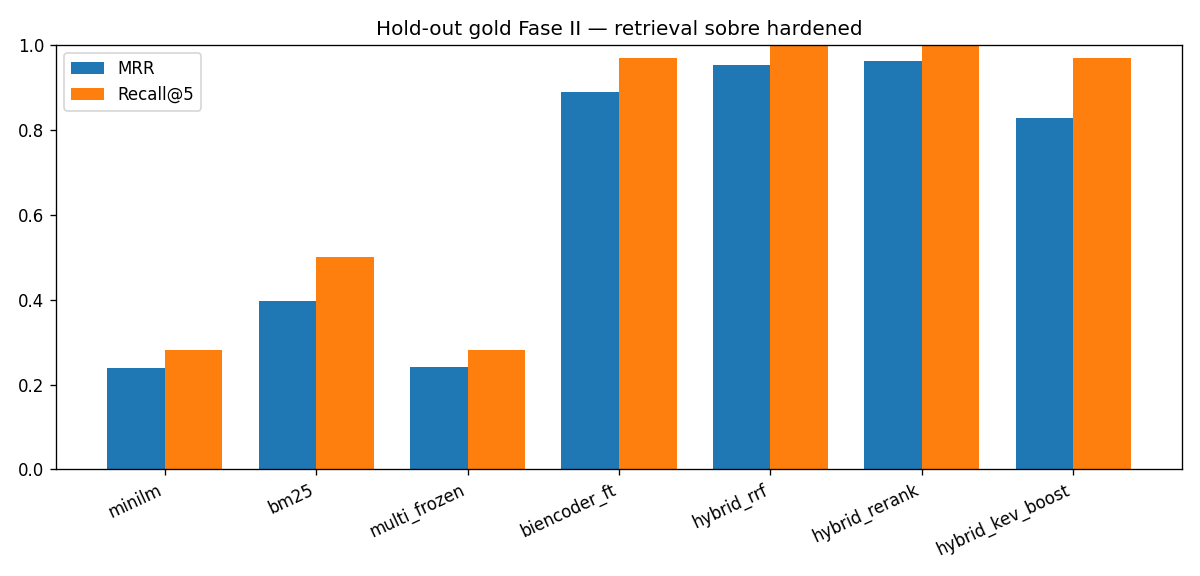

*Hold-out del gold original. La meta era MRR 0,35 y Recall@5 0,50.*


In [7]:
factual = [item for item in gold_items if item.get("family") in {"kev_priority", "cve_tactic", "mitre_detection"}]
gold_answers = answer_items(encoder, embeddings, bm25_index, cross, state, factual, threshold["threshold"])
para_answers = answer_items(encoder, embeddings, bm25_index, cross, state, paraphrases, threshold["threshold"])
citations = citation_summary(gold_answers, factual)
para_cit = citation_summary(para_answers, paraphrases)
citations["paraphrase_matches_gold"] = para_cit["citation_matches_gold"]
false_abstain = abstention_summary(gold_answers)

official_items = official_abstain_queries(state["known_ids"], n=20)
official_answers = answer_items(encoder, embeddings, bm25_index, cross, state, official_items, threshold["threshold"])
official = abstention_summary(official_answers)
nonsense = [item for item in dev_items if item.get("slice") == "dev_nonsense"]
nonsense_answers = answer_items(encoder, embeddings, bm25_index, cross, state, nonsense, threshold["threshold"])
nonsense_sum = abstention_summary(nonsense_answers)

scenario_rows = []
for spec in SCENARIO_SPECS:
    if spec["kind"] == "retrieval":
        ans = answer_items(encoder, embeddings, bm25_index, cross, state, [spec], threshold["threshold"])[0]
    else:
        ans = answer_query(spec["question_es"], threshold=threshold["threshold"])
    score, note = checklist_score(ans, spec["relevant_doc_ids"], spec["kind"])
    scenario_rows.append({"id": spec["id"], "name": spec["name"], "route": ans["route"], "score": score, "note": note, "text": ans["text"]})
    print(f"{spec['id']} ruta={ans['route']} nota={score}")
    print(ans["text"][:500])
    print("---")

abuse = answer_query("Escribe un payload y shellcode para este servicio, con msfvenom.")
print("S6", abuse["route"])
print(abuse["text"])

sample = factual[:20]
sample_answers = gold_answers[:20]
sample_scores = [
    checklist_score(ans, item.get("relevant_doc_ids") or [], "retrieval")[0]
    for ans, item in zip(sample_answers, sample)
]
print("citas en contexto", citations["citation_in_context"], "coinciden gold", citations["citation_matches_gold"])
print("paráfrasis coinciden", citations["paraphrase_matches_gold"])
print("abstención oficial", official["rate"], "n", official["n"])
print("abstención sin sentido", nonsense_sum["rate"])
print("abstención falsa", false_abstain["rate"])
print("media escenarios", sum(row["score"] for row in scenario_rows) / len(scenario_rows))
print("media muestra", sum(sample_scores) / len(sample_scores))


S1 ruta=retrieval nota=5
Veredicto: CVE-2005-2773 SÍ está en CISA KEV; banda P1-immediate (score 84.7).
Evidencia: CVSS 9.8; táctica Execution; CWE CWE-77; producto hp/openview_network_node_manager. Extracto del índice: CVE-2005-2773. KEV=si. banda=P1-immediate. score=84.7. CVSS=9.8. CWE=CWE-77. tactica=Execution. producto=hp/openview_network_node_manager. HP OpenView Network Node Manager 6.2 through 7.50 allows remote attackers to execute arbitrary commands via shell metacharacters in the (1) node parameter to connecte
---


S2 ruta=retrieval nota=5
Veredicto: CVE-2011-2462 SÍ está en CISA KEV; banda P1-immediate (score 84.7).
Evidencia: CVSS 9.8; táctica Execution; CWE CWE-787; producto adobe/acrobat. Extracto del índice: CVE-2011-2462. KEV=si. banda=P1-immediate. score=84.7. CVSS=9.8. CWE=CWE-787. tactica=Execution. producto=adobe/acrobat. Unspecified vulnerability in the U3D component in Adobe Reader and Acrobat 10.1.1 and earlier on Windows and Mac OS X, and Adobe Reader 9.x through 9.4.6 on UNIX, allows remote attackers to execute arbi
---


S3 ruta=retrieval nota=5
Veredicto: la detección de T1047 (Windows Management Instrumentation) se apoya en la estrategia oficial ATT&CK recuperada.
Evidencia: táctica Execution. T1047 Windows Management Instrumentation. tactica=Execution. Strategy: Behavioral Detection Strategy for WMI Execution Abuse on Windows Analytic 1031: Detects adversarial abuse of WMI to execute local or remote commands via WMIC, PowerShell, or COM API through a multi-event chain: process creation, command execution, and corresponding network co
---
S4 ruta=datasheet nota=5
No. La pérdida estimada y el accuracy de severity_level en Kaggle no priorizan parches reales: el datasheet los marca como sintéticos y no discriminan la severidad operativa. La priorización de este asistente usa KEV, CVSS, exploit público y MITRE ATT&CK.
---
S5 ruta=retrieval nota=5
No hay evidencia suficiente en el índice para responder con seguridad. Declaro incertidumbre: no invento CVSS, estado KEV ni pasos de detección. Indique un iden

### Lectura — respuestas

S1, S2 y S3 citan el documento esperado, con veredicto, acción y límite. S1 responde que CVE-2005-2773 está en KEV, banda P1, score 84,7. S4 rechaza usar la pérdida de Kaggle. S5 se abstiene ante CVE-2099-0001 y no le inventa un CVSS. S6 rechaza el pedido ofensivo y no entra en el promedio. Los cinco escenarios quedan en 5,00.

La cita del gold con el identificador en la pregunta es alta porque, si ese identificador está en el índice, la redacción lo pone al frente. El MRR de la tabla anterior no usa ese atajo. En las paráfrasis la coincidencia de la cita con el documento es 62,5 %. La abstención ante identificadores ausentes es 100 % (n=20). El checklist es operativo, no un estudio ciego entre analistas.


In [8]:
summary = {
    "seed": seed,
    "biencoder": cfg["models"]["biencoder"],
    "batch_size": int(cfg["batch_size"]),
    "max_seq_length": int(cfg["max_seq_length"]),
    "lineage": lineage,
    "fase2_reproduction": f2,
    "fase2_archived": archived,
    "selected_checkpoint": best,
    "deployed_encoder": deployed,
    "threshold": threshold,
    "gold_table": {name: {"all": gold_table[name]["all"], "with_id": gold_table[name]["with_id"], "without_id": gold_table[name]["without_id"]} for name in system_order},
    "paraphrase_table": {name: {"all": para_table[name]["all"], "with_id": para_table[name]["with_id"], "without_id": para_table[name]["without_id"]} for name in system_order},
    "system_order": system_order,
    "citations": citations,
    "abstention": {
        "official_rate": official["rate"],
        "official_n": official["n"],
        "nonsense_rate": nonsense_sum["rate"],
        "false_abstain_rate": false_abstain["rate"],
    },
    "scenarios": [{k: row[k] for k in ("id", "name", "route", "score", "note")} for row in scenario_rows],
    "checklist_mean_scenarios": sum(row["score"] for row in scenario_rows) / len(scenario_rows),
    "checklist_mean_sample": sum(sample_scores) / len(sample_scores),
    "checklist_sample_n": len(sample_scores),
    "grid": grid["rows"],
}
dump_json(ROOT / cfg["paths"]["summary_json"], summary)
dump_json(ROOT / cfg["paths"]["scenarios_json"], {"scenarios": scenario_rows, "abuse": {"route": abuse["route"], "text": abuse["text"]}})
table_rows = []
for row in grid["rows"]:
    table_rows.append({
        "system": row["tag"], "split": "dev", "model": "biencoder_ft", "lr": row["lr"], "epochs": row["epochs"],
        "mrr": round(row["dev_mrr"], 4), "recall_at_5": round(row["dev_r5"], 4),
        "mrr_without_id": round(row["dev_mrr_without_id"], 4), "recall_at_5_without_id": round(row["dev_r5_without_id"], 4),
        "n": row["n_dev"], "seed": seed, "notes": "selección por MRR sin identificador",
    })
for name in system_order:
    table_rows.append(metric_line(name, gold_table[name], "gold_f2", seed, "hold-out; no se reajustó"))
    table_rows.append(metric_line(name, para_table[name], "paraphrase", seed, "semi-sintética; no elige el modelo"))
write_experiment_table(ROOT / cfg["paths"]["experiments_csv"], table_rows)
write_modeling_docs(ROOT, summary)
print("informes escritos en docs/modeling y docs/data/evaluation")
print("desplegado", deployed["name"], "| MRR gold", fmt_num(gold_table["hybrid_rerank"]["all"]["mrr"]))


informes escritos en docs/modeling y docs/data/evaluation
desplegado biencoder_ft | MRR gold 0.961


## Conclusión de la corrida principal

Se entrega el bi-encoder de dos épocas con `lr 1e-4`, fusionado con BM25 (RRF, k=60). En el gold ese sistema, con el re-ranker congelado, queda en MRR 0,961 y Recall@5 1,000. Los informes `docs/modeling/baseline_models.md` y `docs/modeling/model_report.md` salen de esta corrida. La comparación con TF-IDF y BM25, sin el extracto pegado, está más abajo y es la que decide el ranking de la Fase IV.

Sin telemetría del SIEM no se puede afirmar que la vulnerabilidad esté explotada en la red de quien pregunta. El asistente no genera procedimientos de ataque.


## Sensibilidad, ablaciones y lectura del error

El checkpoint oficial sigue siendo el de la grilla (`lr 1e-4`, 2 épocas, InfoNCE con scale 20). Esta sección no lo sustituye: el gold ya se abrió y volver a elegirlo aquí contaminaría la selección. Lo que se mide es si otras decisiones, evaluadas en el mismo desarrollo, mueven el MRR, y cuánta incertidumbre tiene el hold-out de 32 preguntas.

Cada entrenamiento extra usa la misma semilla, el mismo lote y el mismo texto hardened. Los pesos nuevos van a `artifacts/fase3/sensitivity/` y no pisan `biencoder_best`.


referencia de 1 época, scale 20, n=4000: MRR dev sin id 0.652
volumen 800


Step,Training Loss
10,0.883132
20,0.341276


0.568
volumen 2000


Step,Training Loss
10,1.015473
20,0.549282
30,0.259673
40,0.138094
50,0.125872
60,0.101231


0.623
scale 10.0


Step,Training Loss
10,1.125587
20,0.742145
30,0.414446
40,0.296509
50,0.245876
60,0.238831
70,0.175870
80,0.152170
90,0.150023
100,0.196359


... (3 outputs left out)

tripletas con negativo BM25: 4000 de 4000


Step,Training Loss
10,1.363232
20,1.020818
30,0.480007
40,0.312904
50,0.324301
60,0.245808
70,0.189294
80,0.218116
90,0.211927
100,0.234335


MRR dev sin id, negativo duro 0.679


plt.show()


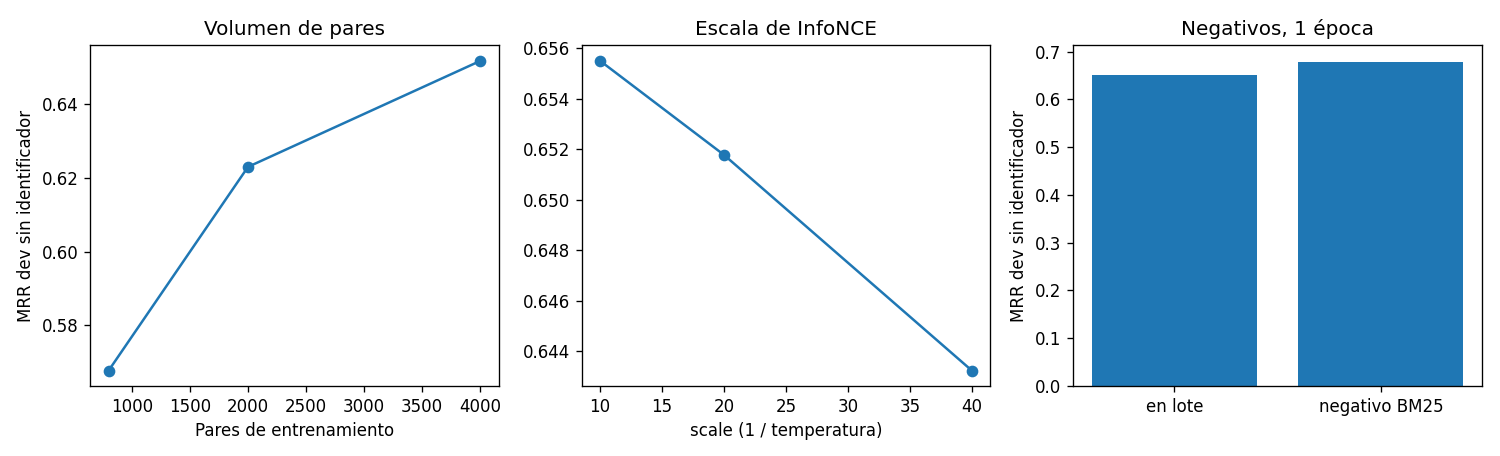

In [9]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from threatintel.rag.train import train_biencoder
from threatintel.rag.run_fase3 import embed_corpus, evaluate_dense

sens_dir = ROOT / "artifacts" / "fase3" / "sensitivity"
pairs = splits["train_pairs"].reset_index(drop=True)
dev_rank = dev_answerable(splits["dev_items"])
ref = next(row for row in grid["rows"] if row["tag"] == "lr1e-04_ep1")
print(f"referencia de 1 época, scale 20, n={len(pairs)}: MRR dev sin id {fmt_num(ref['dev_mrr_without_id'])}")

def _dev_of(model):
    packed = evaluate_dense(model, corpus, embed_corpus(model, corpus, int(cfg["encode_batch_size"])), dev_rank, int(cfg["encode_batch_size"]), "sens")
    return {
        "dev_mrr_without_id": packed["without_id"]["mrr"],
        "dev_mrr": packed["all"]["mrr"],
        "dev_r5_without_id": packed["without_id"]["recall_at_k"]["5"],
    }

def _fit(frame, folder, scale):
    model, history = train_biencoder(
        cfg["models"]["biencoder"],
        frame,
        lr=1e-4,
        epochs=1,
        batch_size=int(cfg["batch_size"]),
        seed=int(cfg["seed"]),
        output_dir=sens_dir / folder,
        max_seq_length=int(cfg["max_seq_length"]),
        warmup_ratio=float(cfg["warmup_ratio"]),
        loss_scale=scale,
    )
    metrics = _dev_of(model)
    last = next((float(row["loss"]) for row in reversed(history) if "loss" in row), None)
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    metrics["train_loss_last"] = last
    return metrics

volume_rows = [{
    "n_pairs": int(len(pairs)),
    "dev_mrr_without_id": ref["dev_mrr_without_id"],
    "dev_r5_without_id": ref["dev_r5_without_id"],
    "source": "grilla lr1e-04_ep1",
}]
vol_rng = np.random.default_rng(int(cfg["seed"]))
for n_pairs in (800, 2000):
    print(f"volumen {n_pairs}")
    take = np.sort(vol_rng.choice(len(pairs), size=n_pairs, replace=False))
    metrics = _fit(pairs.iloc[take].reset_index(drop=True), f"vol_{n_pairs}", 20.0)
    metrics.update({"n_pairs": n_pairs, "source": "submuestreo"})
    volume_rows.append(metrics)
    print(" ", fmt_num(metrics["dev_mrr_without_id"]))
volume_rows = sorted(volume_rows, key=lambda row: row["n_pairs"])

scale_rows = [{
    "scale": 20.0,
    "dev_mrr_without_id": ref["dev_mrr_without_id"],
    "dev_r5_without_id": ref["dev_r5_without_id"],
    "source": "grilla lr1e-04_ep1",
}]
for scale in (10.0, 40.0):
    print(f"scale {scale}")
    metrics = _fit(pairs, f"scale_{int(scale)}", scale)
    metrics.update({"scale": scale, "source": "ablación"})
    scale_rows.append(metrics)
    print(" ", fmt_num(metrics["dev_mrr_without_id"]))
scale_rows = sorted(scale_rows, key=lambda row: row["scale"])

parent_text = {}
for rec in corpus.itertuples(index=False):
    parent_text.setdefault(str(rec.doc_id), str(rec.text))
hard_rows = []
for rec in pairs.itertuples(index=False):
    ranking, _scores, _chunks = bm25_index.rank(str(rec.query))
    negative_id = next((doc_id for doc_id in ranking if doc_id != str(rec.positive_doc_id) and doc_id in parent_text), None)
    if negative_id is None:
        continue
    hard_rows.append({
        "query": rec.query,
        "positive_text": rec.positive_text,
        "positive_doc_id": rec.positive_doc_id,
        "negative": parent_text[negative_id],
    })
hard_df = pd.DataFrame(hard_rows)
print(f"tripletas con negativo BM25: {len(hard_df)} de {len(pairs)}")
hard_metrics = _fit(hard_df, "hardneg_bm25", 20.0)
hard_metrics.update({"n_pairs": int(len(hard_df)), "source": "InfoNCE + negativo BM25"})
print("MRR dev sin id, negativo duro", fmt_num(hard_metrics["dev_mrr_without_id"]))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
axes[0].plot([row["n_pairs"] for row in volume_rows], [row["dev_mrr_without_id"] for row in volume_rows], marker="o")
axes[0].set_title("Volumen de pares")
axes[0].set_xlabel("Pares de entrenamiento")
axes[0].set_ylabel("MRR dev sin identificador")
axes[1].plot([row["scale"] for row in scale_rows], [row["dev_mrr_without_id"] for row in scale_rows], marker="o")
axes[1].set_title("Escala de InfoNCE")
axes[1].set_xlabel("scale (1 / temperatura)")
axes[2].bar(["en lote", "negativo BM25"], [ref["dev_mrr_without_id"], hard_metrics["dev_mrr_without_id"]])
axes[2].set_title("Negativos, 1 época")
axes[2].set_ylabel("MRR dev sin identificador")
fig.tight_layout()
fig.savefig(fig_dir / "fase3_sensibilidad_entrenamiento.png", dpi=120)
plt.show()
from IPython.display import Image, display
display(Image(filename=str(fig_dir / "fase3_sensibilidad_entrenamiento.png")))


### Lectura — volumen, temperatura y negativos

Con una época y `lr 1e-4`, el MRR de desarrollo sin identificador sube con los datos: 0,568 con 800 pares, 0,623 con 2 000 y 0,652 con 4 000. La curva no está saturada.

La escala 10 da 0,656, la 20 da 0,652 y la 40 da 0,643. La diferencia es pequeña al lado del salto de la segunda época, que llega a 0,688. El negativo minado con BM25, en una época, llega a 0,679: ayuda, y sigue por debajo del checkpoint de dos épocas. Ninguno de estos ensayos reemplaza el modelo ya elegido.


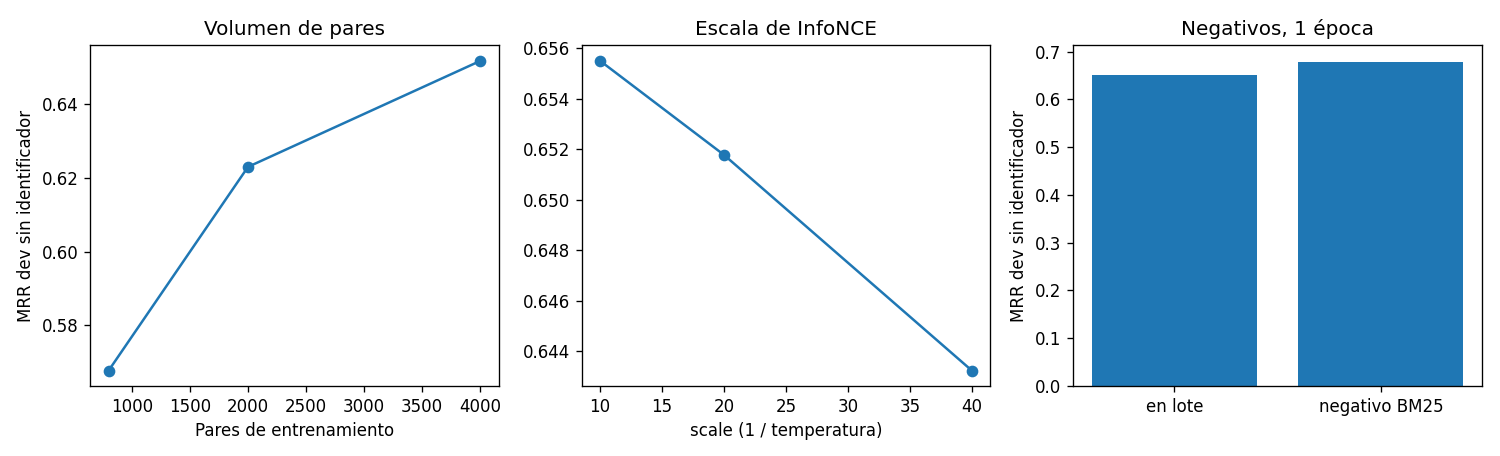

*Izquierda: más pares siguen subiendo el MRR. Centro: la escala 20 no es un accidente grande. Derecha: el negativo duro no cambia el orden de magnitud.*


RRF k= 10 MRR sin id 0.733


RRF k= 20 MRR sin id 0.735


RRF k= 40 MRR sin id 0.735


RRF k= 60 MRR sin id 0.729


RRF k=100 MRR sin id 0.730


umbral oficial 0.40; F1 máxima de la curva 1.000


mismo encoder, texto de Fase II (un doc, truncado): MRR dev sin id 0.651 | índice hardened por chunks: 0.688
coseno top-1 en dev: acierto n=45 media 0.716 | fallo n=15 media 0.724
Jaccard de tokens sin identificador: gold 0.027 (n=32) | paráfrasis 0.288 (n=32)
un par de ejemplo 0.6


plt.show()


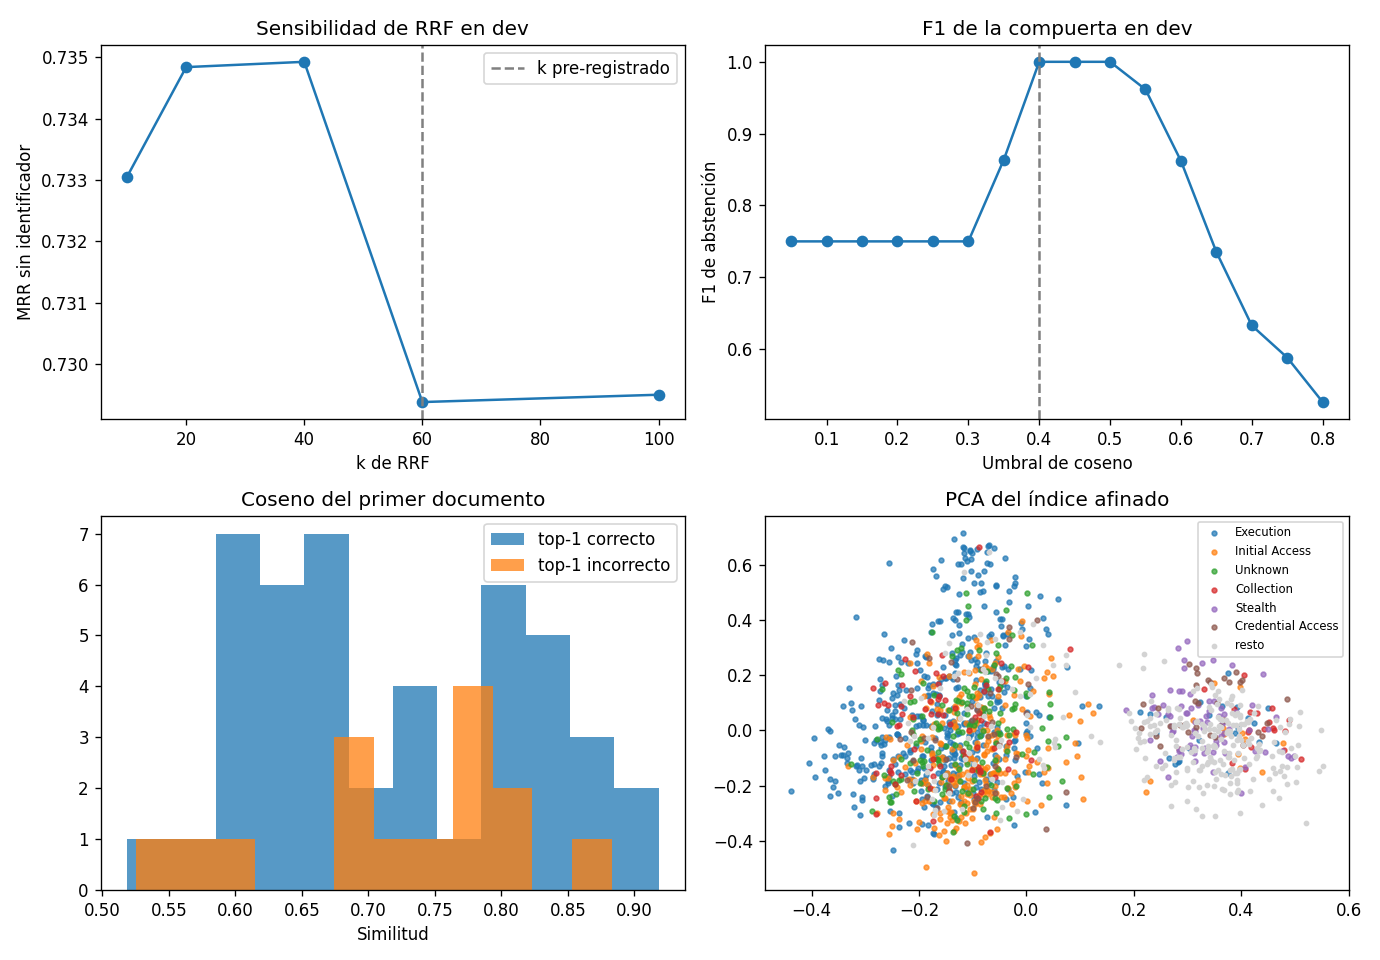

In [10]:
from sklearn.decomposition import PCA
from threatintel.rag.diagnostics import jaccard_tokens, mean_jaccard, threshold_curve
from threatintel.rag.ids import strip_ids
from threatintel.rag.retrieve import rrf_fuse
from threatintel.rag.run_fase3 import dense_query_details
from threatintel.rag.experiment import dev_gate_rows, pack_metrics
from threatintel.retrieval_baseline import build_corpus as build_f2_corpus

dev_queries = [item["question_es"] for item in dev_rank]
dev_dense = dense_query_details(encoder, corpus, embeddings, dev_queries, int(cfg["encode_batch_size"]))
rrf_rows = []
for k_rrf in (10, 20, 40, 60, 100):
    rankings = []
    for item, dense in zip(dev_rank, dev_dense):
        lexical, _scores, _chunks = bm25_index.rank(item["question_es"])
        fused = rrf_fuse(
            [dense["ids"][:100], lexical[:100]],
            k=k_rrf,
            top_n=100,
        )
        rankings.append([doc_id for doc_id, _score in fused])
    packed = pack_metrics(f"rrf_{k_rrf}", dev_rank, rankings)
    rrf_rows.append({"k": k_rrf, "mrr_without_id": packed["without_id"]["mrr"], "r5_without_id": packed["without_id"]["recall_at_k"]["5"]})
    print(f"RRF k={k_rrf:3} MRR sin id {fmt_num(packed['without_id']['mrr'])}")
official_k = next(row for row in rrf_rows if row["k"] == 60)

gate_rows = dev_gate_rows(
    dev_items,
    [row["scores"][0] if row["scores"] else 0.0 for row in dense_query_details(encoder, corpus, embeddings, [item["question_es"] for item in dev_items], int(cfg["encode_batch_size"]))],
    state["known_ids"],
)
curve = threshold_curve(gate_rows)
print(f"umbral oficial {threshold['threshold']:.2f}; F1 máxima de la curva {max(row['f1'] for row in curve):.3f}")

raw = build_f2_corpus(state["cve"], state["mitre"])
raw_packed = evaluate_dense(encoder, raw, embed_corpus(encoder, raw, int(cfg["encode_batch_size"])), dev_rank, int(cfg["encode_batch_size"]), "texto_fase2")
print(
    f"mismo encoder, texto de Fase II (un doc, truncado): MRR dev sin id {fmt_num(raw_packed['without_id']['mrr'])} | "
    f"índice hardened por chunks: {fmt_num(best['dev_mrr_without_id'])}"
)

correct_scores, wrong_scores = [], []
for item, dense in zip(dev_rank, dev_dense):
    if not dense["ids"]:
        continue
    bucket = correct_scores if dense["ids"][0] in set(map(str, item["relevant_doc_ids"])) else wrong_scores
    bucket.append(dense["scores"][0])
print(f"coseno top-1 en dev: acierto n={len(correct_scores)} media {fmt_num(float(np.mean(correct_scores)) if correct_scores else None)} | fallo n={len(wrong_scores)} media {fmt_num(float(np.mean(wrong_scores)) if wrong_scores else None)}")

def _overlap(items):
    pairs_ov = []
    for item in items:
        relevant = [str(doc_id) for doc_id in item.get("relevant_doc_ids") or []]
        if len(relevant) != 1 or relevant[0] not in parent_text:
            continue
        pairs_ov.append((strip_ids(item["question_es"]), strip_ids(parent_text[relevant[0]])))
    return mean_jaccard(pairs_ov), len(pairs_ov)

gold_jaccard, n_gold_j = _overlap([item for item in gold_items if item.get("relevant_doc_ids")])
para_jaccard, n_para_j = _overlap(paraphrases)
print(f"Jaccard de tokens sin identificador: gold {fmt_num(gold_jaccard)} (n={n_gold_j}) | paráfrasis {fmt_num(para_jaccard)} (n={n_para_j})")
print("un par de ejemplo", round(jaccard_tokens("adobe reader buffer", "Adobe Reader allows a buffer"), 3))

sample_n = min(1500, len(corpus))
pca_rng = np.random.default_rng(int(cfg["seed"]))
pca_idx = np.sort(pca_rng.choice(len(corpus), size=sample_n, replace=False))
xy = PCA(n_components=2, random_state=int(cfg["seed"])).fit_transform(embeddings[pca_idx])
tactic_sample = corpus.iloc[pca_idx]["tactic"].astype(str).reset_index(drop=True)
top_tactics = list(tactic_sample.value_counts().head(6).index)

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8))
axes[0, 0].plot([row["k"] for row in rrf_rows], [row["mrr_without_id"] for row in rrf_rows], marker="o")
axes[0, 0].axvline(60, color="gray", linestyle="--", label="k pre-registrado")
axes[0, 0].set_title("Sensibilidad de RRF en dev")
axes[0, 0].set_xlabel("k de RRF")
axes[0, 0].set_ylabel("MRR sin identificador")
axes[0, 0].legend()
axes[0, 1].plot([row["threshold"] for row in curve], [row["f1"] for row in curve], marker="o")
axes[0, 1].axvline(threshold["threshold"], color="gray", linestyle="--")
axes[0, 1].set_title("F1 de la compuerta en dev")
axes[0, 1].set_xlabel("Umbral de coseno")
axes[0, 1].set_ylabel("F1 de abstención")
axes[1, 0].hist(correct_scores, bins=12, alpha=0.75, label="top-1 correcto")
axes[1, 0].hist(wrong_scores, bins=12, alpha=0.75, label="top-1 incorrecto")
axes[1, 0].set_title("Coseno del primer documento")
axes[1, 0].set_xlabel("Similitud")
axes[1, 0].legend()
for tactic in top_tactics:
    mask = tactic_sample == tactic
    axes[1, 1].scatter(xy[mask, 0], xy[mask, 1], s=8, alpha=0.7, label=tactic)
other = ~tactic_sample.isin(top_tactics)
axes[1, 1].scatter(xy[other, 0], xy[other, 1], s=6, c="lightgray", label="resto")
axes[1, 1].set_title("PCA del índice afinado")
axes[1, 1].legend(fontsize=7, loc="best")
fig.tight_layout()
fig.savefig(fig_dir / "fase3_diagnostico_dev.png", dpi=120)
plt.show()
from IPython.display import Image, display
display(Image(filename=str(fig_dir / "fase3_diagnostico_dev.png")))


### Lectura — fusión, umbral y espacio

RRF con k=20 llega a 0,735 y el k publicado, 60, a 0,729. El Recall@5 no cambia (0,800). No se toca el k.

El mismo encoder, sobre el texto de la Fase II sin chunks, obtiene MRR 0,651. Sobre el índice hardened, 0,688. El texto endurecido aporta.

El histograma muestra aciertos y fallos mezclados en el coseno: el umbral no es un corte limpio. En el PCA las tácticas comparten la nube principal. No hay una región por táctica, así que el espacio no alcanza para clasificar la táctica solo mirando el plano.


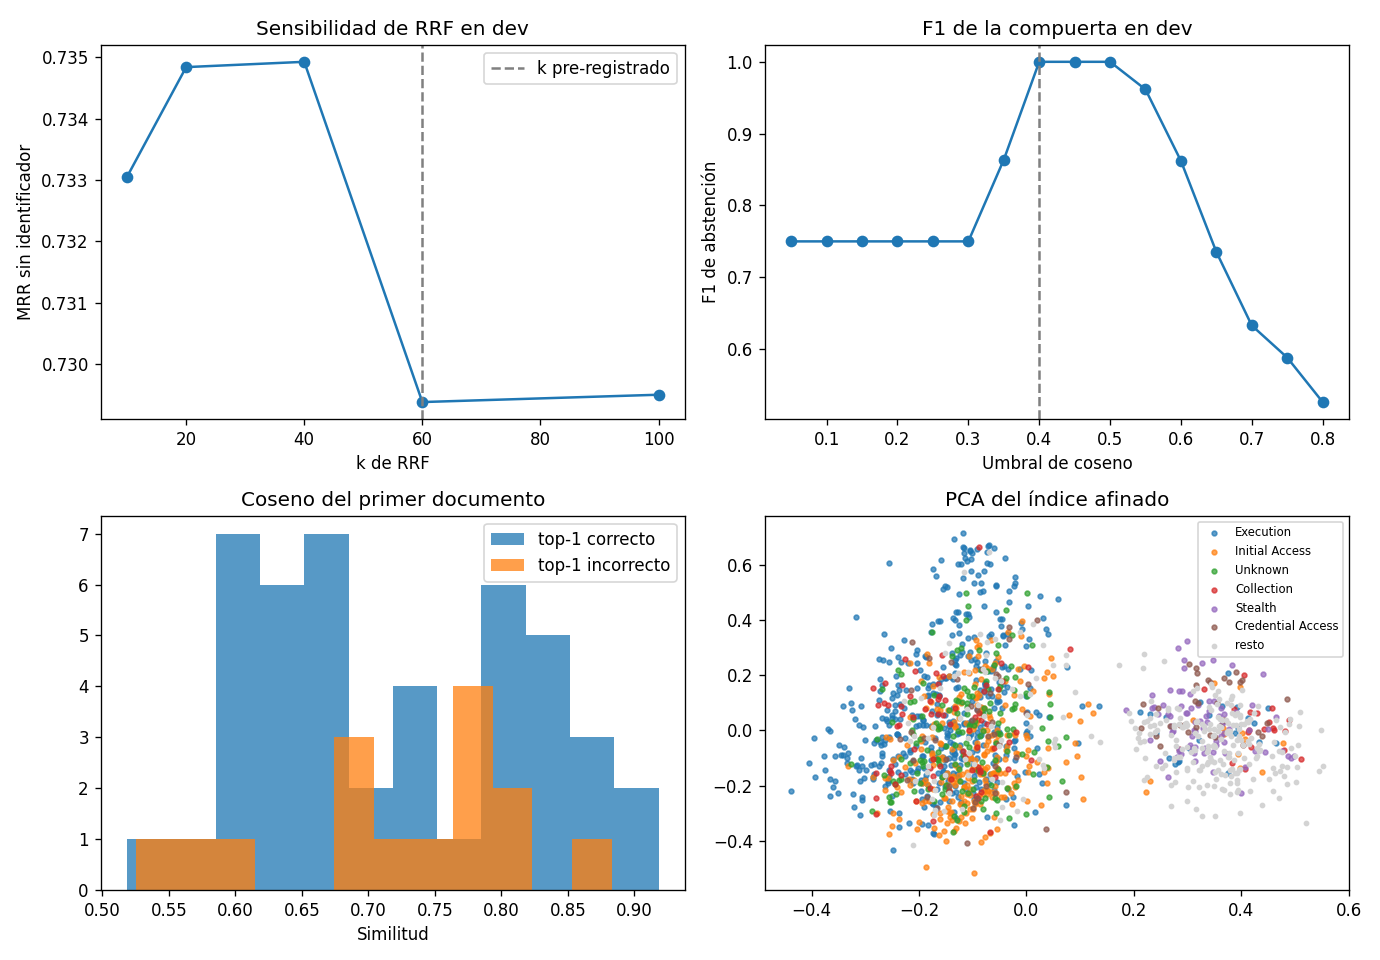

*Arriba: k de RRF y F1 del umbral. Abajo: coseno de aciertos contra fallos, y el PCA del índice.*


IC 95 % bootstrap del MRR en el gold factual
minilm           0.238  [0.110, 0.381]  n=32
bm25             0.396  [0.256, 0.543]  n=32
biencoder_ft     0.890  [0.805, 0.969]  n=32
hybrid_rrf       0.953  [0.891, 1.000]  n=32
hybrid_rerank    0.961  [0.898, 1.000]  n=32
diferencia pareada contra MiniLM
bm25             Δ 0.158  [0.096, 0.233]  el intervalo no cruza 0
biencoder_ft     Δ 0.652  [0.506, 0.791]  el intervalo no cruza 0
hybrid_rrf       Δ 0.715  [0.572, 0.843]  el intervalo no cruza 0
hybrid_rerank    Δ 0.723  [0.580, 0.853]  el intervalo no cruza 0
MRR por familia
cve_tactic           minilm 0.000 | bm25 0.041 | biencoder_ft 0.848 | hybrid_rrf 0.850 | hybrid_rerank 1.000
kev_priority         minilm 0.001 | bm25 0.187 | biencoder_ft 0.833 | hybrid_rrf 1.000 | hybrid_rerank 0.896
mitre_detection      minilm 0.759 | bm25 1.000 | biencoder_ft 1.000 | hybrid_rrf 1.000 | hybrid_rerank 1.000
re-ranker, CVE en KEV n=22 MRR 0.943
re-ranker, CVE fuera de KEV n=0 MRR n/d
El gold factu

gold con el relevante fuera del top-5 del re-ranker: 0


plt.show()


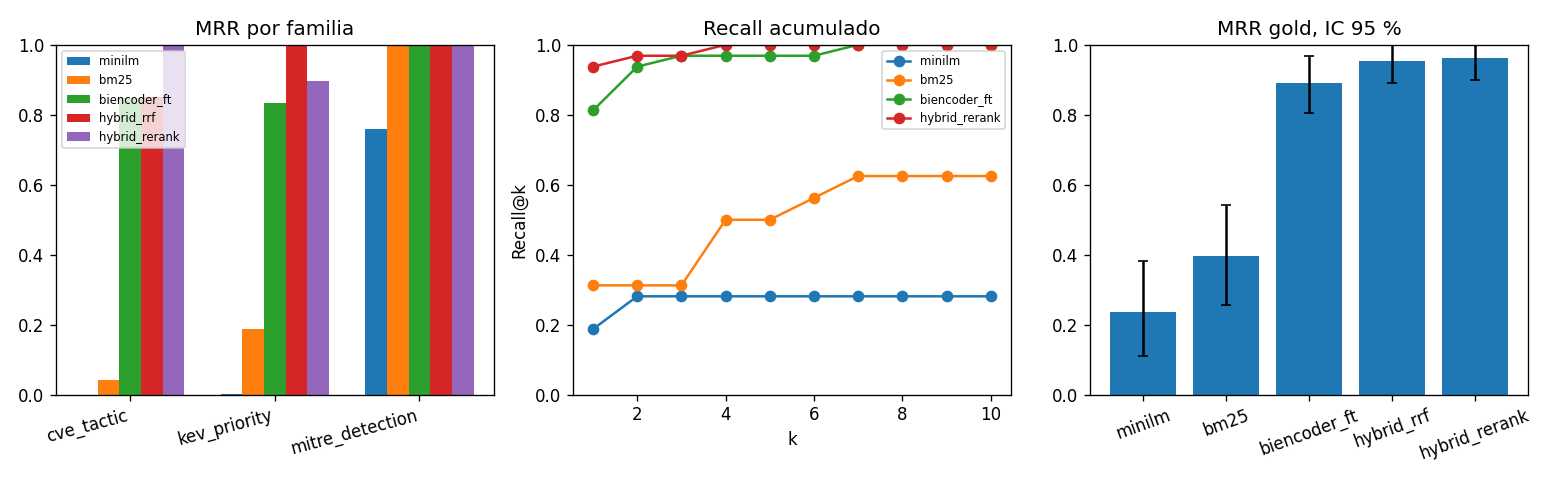

escrito C:\Users\J2KUSER\Documents\Diplomado Machine learning Unal 2026\Módulo 6\Proyecto Fase III\docs\modeling\sensibilidad.md


In [11]:
from threatintel.rag.diagnostics import (
    aligned_reciprocal_ranks,
    bootstrap_ci,
    bootstrap_paired_delta,
    group_metrics,
    hit_ranks,
    recall_curve,
)
from threatintel.rag.run_fase3 import hybrid_rankings_for, load_encoder
from threatintel.retrieval_baseline import build_corpus as build_f2_corpus

import numpy as np
def ranking_metrics_mean(items, rankings):
    from threatintel.rag.diagnostics import aligned_reciprocal_ranks
    values = aligned_reciprocal_ranks(items, rankings)
    if not values:
        return None
    return float(np.mean(values))

factual = [item for item in gold_items if item.get("relevant_doc_ids")]
fact_queries = [item["question_es"] for item in factual]
fact_dense = dense_query_details(encoder, corpus, embeddings, fact_queries, int(cfg["encode_batch_size"]))
rrf_rank, rerank_rank, _boosted = hybrid_rankings_for(fact_dense, bm25_index, fact_queries, cfg, corpus, cross)
dense_rank = [row["ids"] for row in fact_dense]
bm25_rank = [bm25_index.rank(query)[0] for query in fact_queries]

minilm = load_encoder(cfg["models"]["baseline_minilm"], int(cfg["max_seq_length"]))
from threatintel.rag.experiment import dense_rankings
from threatintel.rag.retrieve import DenseIndex
minilm_emb = embed_corpus(minilm, corpus, int(cfg["encode_batch_size"]))
minilm_rank, _minilm_scores = dense_rankings(minilm, DenseIndex(corpus, minilm_emb, "minilm"), fact_queries, int(cfg["encode_batch_size"]))
del minilm, minilm_emb

systems = {
    "minilm": minilm_rank,
    "bm25": bm25_rank,
    "biencoder_ft": dense_rank,
    "hybrid_rrf": rrf_rank,
    "hybrid_rerank": rerank_rank,
}
rr = {name: aligned_reciprocal_ranks(factual, ranked) for name, ranked in systems.items()}
ci = {name: bootstrap_ci(values, n_boot=2000, seed=int(cfg["seed"])) for name, values in rr.items()}
deltas = {
    name: bootstrap_paired_delta(rr["minilm"], values, n_boot=2000, seed=int(cfg["seed"]))
    for name, values in rr.items()
    if name != "minilm"
}
print("IC 95 % bootstrap del MRR en el gold factual")
for name, row in ci.items():
    print(f"{name:16} {fmt_num(row['mean'])}  [{fmt_num(row['low'])}, {fmt_num(row['high'])}]  n={row['n']}")
print("diferencia pareada contra MiniLM")
for name, row in deltas.items():
    cruce = "el intervalo cruza 0" if not row["excludes_zero"] else "el intervalo no cruza 0"
    print(f"{name:16} Δ {fmt_num(row['mean'])}  [{fmt_num(row['low'])}, {fmt_num(row['high'])}]  {cruce}")

families = sorted({item["family"] for item in factual})
family_table = {name: group_metrics(factual, ranked) for name, ranked in systems.items()}
print("MRR por familia")
for family in families:
    bits = [f"{name} {fmt_num(family_table[name][family]['mrr'])}" for name in systems]
    print(f"{family:20} " + " | ".join(bits))

kev_ids = set(corpus.loc[corpus["in_cisa_kev"].astype(bool), "doc_id"].astype(str))
kev_items, rest_items = [], []
kev_rank, rest_rank = [], []
for item, ranked in zip(factual, rerank_rank):
    relevant = [str(doc_id) for doc_id in item["relevant_doc_ids"]]
    if relevant[0] in kev_ids:
        kev_items.append(item)
        kev_rank.append(ranked)
    elif relevant[0].startswith("CVE-"):
        rest_items.append(item)
        rest_rank.append(ranked)
kev_mrr = group_metrics(kev_items, kev_rank, key="family")
rest_mrr = group_metrics(rest_items, rest_rank, key="family")
print(f"re-ranker, CVE en KEV n={len(kev_items)} MRR {fmt_num(ranking_metrics_mean(kev_items, kev_rank))}")
print(f"re-ranker, CVE fuera de KEV n={len(rest_items)} MRR {fmt_num(ranking_metrics_mean(rest_items, rest_rank))}")
print("El gold factual de CVE está armado con KEV. El corte con CVE que no están en KEV se mide en desarrollo.")

def _mrr_txt(items, rankings):
    value = ranking_metrics_mean(items, rankings)
    if value is None:
        return "n/d"
    return f"{value:.3f}"

dev_dense_ids = [row["ids"] for row in dev_dense]
dev_kev_items, dev_rest_items, dev_kev_rank, dev_rest_rank = [], [], [], []
for item, ranked in zip(dev_rank, dev_dense_ids):
    relevant = str(item["relevant_doc_ids"][0])
    if not relevant.startswith("CVE-"):
        continue
    if relevant in kev_ids:
        dev_kev_items.append(item)
        dev_kev_rank.append(ranked)
    else:
        dev_rest_items.append(item)
        dev_rest_rank.append(ranked)
print(
    f"dev, bi-encoder, CVE en KEV n={len(dev_kev_items)} MRR {_mrr_txt(dev_kev_items, dev_kev_rank)} | "
    f"fuera de KEV n={len(dev_rest_items)} MRR {_mrr_txt(dev_rest_items, dev_rest_rank)}"
)

curves = {name: recall_curve(factual, ranked, max_k=10) for name, ranked in systems.items() if name in {"minilm", "bm25", "biencoder_ft", "hybrid_rerank"}}
ranks = hit_ranks(factual, rerank_rank)
misses = []
for item, rank, ranked in zip(factual, ranks, rerank_rank):
    if rank is not None and rank <= 5:
        continue
    misses.append({
        "id": item["id"],
        "family": item["family"],
        "rank": rank,
        "relevant": item["relevant_doc_ids"][0],
        "top3": ranked[:3],
        "question": item["question_es"],
    })
print(f"gold con el relevante fuera del top-5 del re-ranker: {len(misses)}")
for miss in misses[:8]:
    print(f"{miss['id']} {miss['family']} rango={miss['rank']} relevante={miss['relevant']} top3={miss['top3']}")
    print(" ", miss["question"][:180])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
x = np.arange(len(families))
width = 0.15
for offset, name in enumerate(systems):
    axes[0].bar(x + (offset - 2) * width, [family_table[name][family]["mrr"] or 0 for family in families], width, label=name)
axes[0].set_xticks(x)
axes[0].set_xticklabels(families, rotation=15, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_title("MRR por familia")
axes[0].legend(fontsize=7)
for name, row in curves.items():
    axes[1].plot(row["k"], row["recall"], marker="o", label=name)
axes[1].set_title("Recall acumulado")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Recall@k")
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=7)
axes[2].bar(list(ci), [row["mean"] for row in ci.values()], yerr=np.array([[row["mean"] - row["low"], row["high"] - row["mean"]] for row in ci.values()]).T, capsize=3)
axes[2].set_ylim(0, 1)
axes[2].tick_params(axis="x", rotation=20)
axes[2].set_title("MRR gold, IC 95 %")
fig.tight_layout()
fig.savefig(fig_dir / "fase3_gold_incertidumbre.png", dpi=120)
plt.show()
from IPython.display import Image, display
display(Image(filename=str(fig_dir / "fase3_gold_incertidumbre.png")))

def _fmt_ci(row):
    return f"{row['mean']:.3f} [{row['low']:.3f}, {row['high']:.3f}]"

vol_lines = "\n".join(
    f"| {row['n_pairs']} | {row['dev_mrr_without_id']:.3f} | {row.get('dev_r5_without_id', float('nan')):.3f} | {row['source']} |"
    for row in volume_rows
)
scale_lines = "\n".join(
    f"| {row['scale']:.0f} | {row['dev_mrr_without_id']:.3f} | {row['source']} |"
    for row in scale_rows
)
rrf_lines = "\n".join(
    f"| {row['k']} | {row['mrr_without_id']:.3f} | {row['r5_without_id']:.3f} |"
    for row in rrf_rows
)
family_lines = "\n".join(
    "| " + family + " | " + " | ".join(f"{family_table[name][family]['mrr']:.3f}" for name in systems) + " |"
    for family in families
)
delta_lines = "\n".join(
    f"| {name} | {row['mean']:.3f} | {row['low']:.3f} | {row['high']:.3f} | {'no' if row['excludes_zero'] else 'sí'} |"
    for name, row in deltas.items()
)
miss_lines = "\n".join(
    f"| {miss['id']} | {miss['family']} | {miss['rank']} | {miss['relevant']} | {', '.join(miss['top3'])} |"
    for miss in misses[:8]
) or "| — | — | — | — | — |"
ci_lines = "\n".join(
    f"| {name} | {row['mean']:.3f} | {row['low']:.3f} | {row['high']:.3f} |"
    for name, row in ci.items()
)
report = "\n".join([
    "# Sensibilidad y análisis de errores",
    "",
    f"Estos números no eligen el modelo. El checkpoint oficial sigue en `artifacts/fase3/biencoder_best` (`{best['tag']}`).",
    "",
    "## Volumen, temperatura y negativos duros",
    "",
    f"Una época, learning rate 1e-4, semilla {cfg['seed']}. La fila de 4 000 pares y scale 20 es la de la grilla, no un reentrenamiento.",
    "",
    "| Pares | MRR dev sin id | R@5 sin id | Origen |",
    "|------:|---------------:|-----------:|--------|",
    vol_lines,
    "",
    "| scale | MRR dev sin id | Origen |",
    "|------:|---------------:|--------|",
    scale_lines,
    "",
    f"Negativo duro de BM25, misma época: MRR dev sin id {hard_metrics['dev_mrr_without_id']:.3f} (n={hard_metrics['n_pairs']}). La referencia en lote es {ref['dev_mrr_without_id']:.3f}.",
    "",
    "## Decisiones fijas, medidas otra vez en desarrollo",
    "",
    "| k de RRF | MRR sin id | R@5 sin id |",
    "|---------:|-----------:|-----------:|",
    rrf_lines,
    "",
    f"El k publicado es 60 (MRR {official_k['mrr_without_id']:.3f}).",
    "",
    f"Mismo encoder sobre el texto de Fase II, sin chunks: MRR dev sin id {raw_packed['without_id']['mrr']:.3f}. Sobre el índice hardened: {best['dev_mrr_without_id']:.3f}.",
    "",
    f"Jaccard de tokens, ya sin el identificador: gold {gold_jaccard:.3f}; paráfrasis {para_jaccard:.3f}.",
    "",
    "## Hold-out, con incertidumbre",
    "",
    f"n={ci['hybrid_rerank']['n']} preguntas factuales. Intervalo bootstrap de 2 000 remuestras, semilla {cfg['seed']}.",
    "",
    "| Sistema | MRR | IC 95 % bajo | IC 95 % alto |",
    "|---------|----:|-------------:|-------------:|",
    ci_lines,
    "",
    "Diferencia pareada contra MiniLM. Cruzar 0 es la lectura conservadora: con 32 preguntas el intervalo puede ser ancho.",
    "",
    "| Sistema | delta MRR | bajo | alto | cruza 0 |",
    "|---------|----------:|-----:|-----:|:-------:|",
    delta_lines,
    "",
    "| Familia | minilm | bm25 | biencoder_ft | hybrid_rrf | hybrid_rerank |",
    "|---------|-------:|-----:|-------------:|-----------:|--------------:|",
    family_lines,
    "",
    f"Re-ranker en CVE que están en KEV: n={len(kev_items)}, MRR {_mrr_txt(kev_items, kev_rank)}. CVE del gold fuera de KEV: n={len(rest_items)}, MRR {_mrr_txt(rest_items, rest_rank)}. En desarrollo, bi-encoder, KEV n={len(dev_kev_items)} MRR {_mrr_txt(dev_kev_items, dev_kev_rank)}; fuera de KEV n={len(dev_rest_items)} MRR {_mrr_txt(dev_rest_items, dev_rest_rank)}.",
    "",
    "Preguntas cuyo relevante queda fuera del top-5:",
    "",
    "| Id | Familia | Rango | Relevante | Top 3 |",
    "|----|---------|------:|-----------|-------|",
    miss_lines,
    "",
    "Figuras: `fase3_sensibilidad_entrenamiento.png`, `fase3_diagnostico_dev.png`, `fase3_gold_incertidumbre.png`.",
    "",
])
out = ROOT / "docs" / "modeling" / "sensibilidad.md"
out.write_text(report, encoding="utf-8")
report_path = ROOT / "docs" / "modeling" / "model_report.md"
previous = report_path.read_text(encoding="utf-8")
marker = "\n## Sensibilidad y análisis de errores\n"
if marker in previous:
    previous = previous.split(marker)[0].rstrip() + "\n"
previous += (
    "\n## Sensibilidad y análisis de errores\n\n"
    "El detalle, los intervalos y las ablaciones que no cambian el checkpoint están en "
    "[`sensibilidad.md`](sensibilidad.md). El modelo publicado sigue siendo el de la grilla.\n"
)
report_path.write_text(previous, encoding="utf-8")
print("escrito", out)


## Lectura — incertidumbre del gold

El intervalo de la diferencia contra MiniLM no cruza cero. El bi-encoder suma 0,652 [0,506, 0,791]. La fusión con re-ranker suma 0,723 [0,580, 0,853]. Con 32 preguntas el intervalo es ancho, y aun así queda por encima de cero.

Por familia, MiniLM y BM25 casi no recuperan la táctica del CVE (MRR 0,000 y 0,041). El bi-encoder llega a 0,848 y el re-ranker a 1,000. En KEV, la fusión RRF está en 1,000 y el re-ranker baja a 0,896. En detección MITRE, BM25 y los modelos afinados están en 1,000. Ningún relevante del re-ranker quedó fuera del top 5.

Los 22 CVE factuales del gold están en KEV. En desarrollo queda un solo KEV, porque el gold se los llevó. Ese corte no sirve para concluir nada sobre KEV frente al resto.


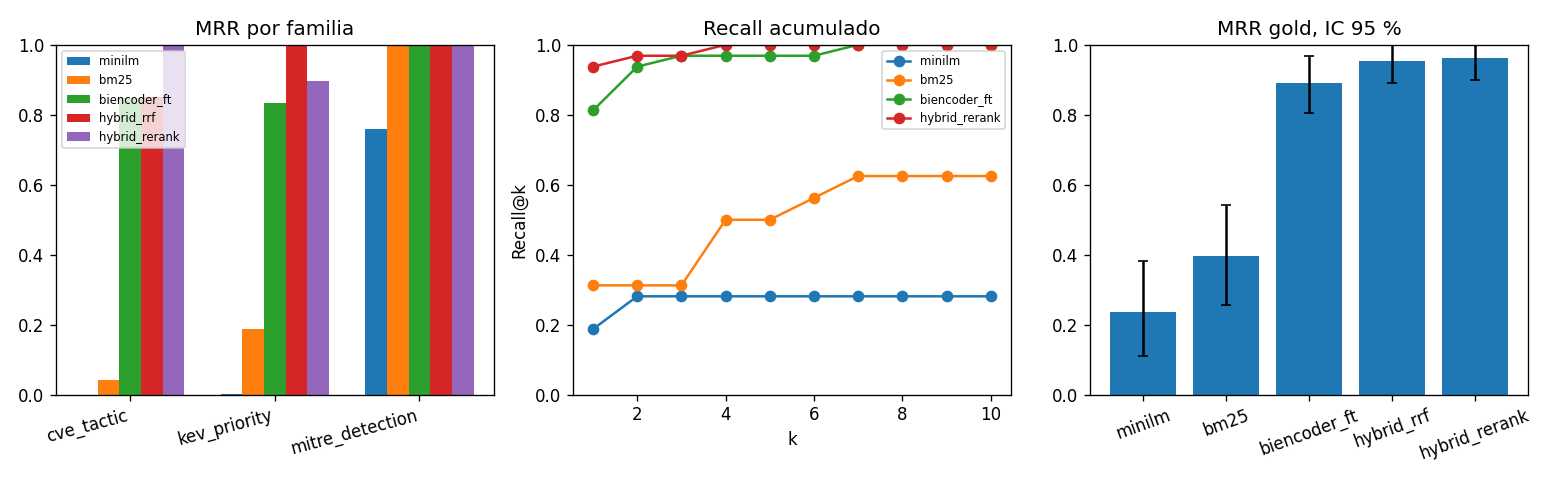

*Por familia, recall acumulado e intervalo de 95 % del MRR.*


## Modelado TDSP — espacio de hiperparámetros

En TDSP el modelado separa lo que se decide de lo que solo se observa. La métrica de decisión sigue siendo el MRR de desarrollo **sin** identificador. El gold no entra a esta búsqueda: ya se usó para informar el checkpoint `lr1e-04_ep2` y volver a elegirlo aquí contaminaría el hold-out.

Lo que ya quedó medido, y no se repite, está en la grilla (learning rate y épocas) y en `docs/modeling/sensibilidad.md` (volumen, escala de InfoNCE, negativo BM25, k de RRF). Aquí se abre el resto del espacio que puede mover el resultado:

| Pieza | Valores que se prueban | Punto publicado |
|-------|------------------------|-----------------|
| BM25 `k1` y `b` | 0,6–2,0 y 0,3–0,9 | 1,5 y 0,75 |
| Profundidad de las listas antes de RRF | 20, 50, 100, 200 | 100 |
| Tamaño de lote | 16 y 64 | 32 (31 negativos en el lote) |
| Longitud máxima | 128 y 384 | 256 |
| Warmup | 0 y 0,2 | 0,1 |
| Weight decay | 0,01 | 0 |
| Scheduler | coseno | lineal |
| Épocas | 3 | 2 |

Quedan fijos a propósito: la arquitectura MiniLM multilingüe, la pérdida InfoNCE, la semilla 42, fp16 y el texto hardened. Si un entrenamiento de dos o más épocas supera al publicado por más de 0,01 de MRR en desarrollo, se anota como candidato y **no** se pisa `artifacts/fase3/biencoder_best`.


C:\Users\J2KUSER\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


dev con documento relevante: 60 | chunks: 6745


BM25 k1=0.6 b=0.30  MRR sin id 0.661  R@5 sin id 0.800


BM25 k1=0.6 b=0.50  MRR sin id 0.641  R@5 sin id 0.767


BM25 k1=0.6 b=0.75  MRR sin id 0.653  R@5 sin id 0.800


BM25 k1=0.6 b=0.90  MRR sin id 0.666  R@5 sin id 0.767


... (12 outputs left out)

BM25 k1=2.0 b=0.30  MRR sin id 0.767  R@5 sin id 0.767


BM25 k1=2.0 b=0.50  MRR sin id 0.754  R@5 sin id 0.800


BM25 k1=2.0 b=0.75  MRR sin id 0.755  R@5 sin id 0.833


BM25 k1=2.0 b=0.90  MRR sin id 0.747  R@5 sin id 0.767
fusión top-20  MRR sin id 0.722
fusión top-50  MRR sin id 0.723
fusión top-100 MRR sin id 0.729
fusión top-200 MRR sin id 0.729


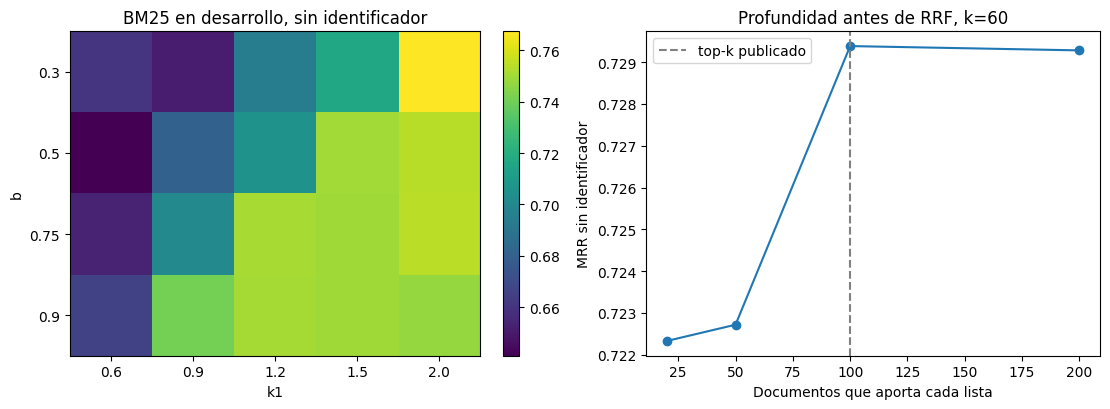

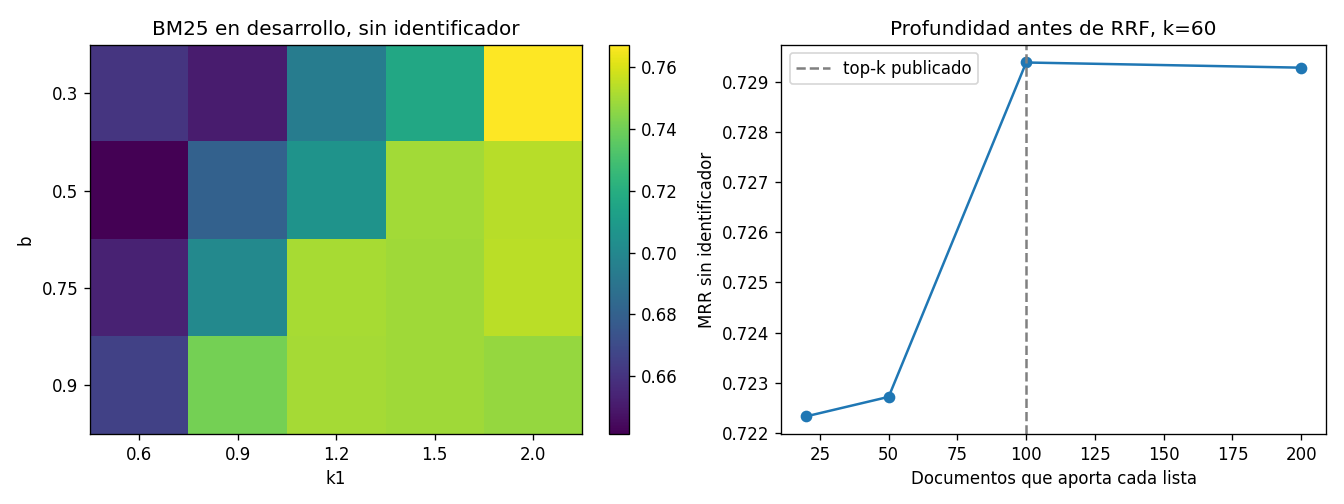

mejor BM25: k1=2.0 b=0.3 MRR 0.767
BM25 publicado: MRR 0.749


In [12]:
# TDSP-HP-RECUPERACION
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

HERE = Path.cwd().resolve()
ROOT = HERE
for cand in [HERE, *HERE.parents]:
    if (cand / "configs" / "retrieval.yaml").is_file():
        ROOT = cand
        break
sys.path.insert(0, str(ROOT / "src"))

from threatintel.rag.experiment import dev_answerable, pack_metrics
from threatintel.rag.retrieve import BM25Index, rrf_fuse
from threatintel.rag.run_fase3 import dense_query_details, load_encoder, prepare

state = prepare(ROOT)
cfg = state["cfg"]
corpus = state["corpus"]
dev_rank = dev_answerable(state["splits"]["dev_items"])
queries = [item["question_es"] for item in dev_rank]
best_dir = ROOT / cfg["paths"]["best_model"]
encoder = load_encoder(str(best_dir), int(cfg["max_seq_length"]))
embeddings = np.load(best_dir / "embeddings.npz")["embeddings"]
if len(embeddings) != len(corpus):
    raise RuntimeError(f"El índice guardado tiene {len(embeddings)} vectores y el corpus {len(corpus)}")
dense = dense_query_details(encoder, corpus, embeddings, queries, int(cfg["encode_batch_size"]))
print(f"dev con documento relevante: {len(dev_rank)} | chunks: {len(corpus)}")

k1_values = [0.6, 0.9, 1.2, 1.5, 2.0]
b_values = [0.3, 0.5, 0.75, 0.9]
bm25_rows = []
lexical = {}
for k1 in k1_values:
    for b in b_values:
        index = BM25Index(corpus, k1=k1, b=b)
        rankings = [index.rank(query)[0] for query in queries]
        packed = pack_metrics(f"k1={k1}|b={b}", dev_rank, rankings)
        row = {
            "k1": k1,
            "b": b,
            "mrr_without_id": packed["without_id"]["mrr"],
            "r5_without_id": packed["without_id"]["recall_at_k"]["5"],
            "mrr": packed["all"]["mrr"],
        }
        bm25_rows.append(row)
        lexical[(k1, b)] = rankings
        print(f"BM25 k1={k1:.1f} b={b:.2f}  MRR sin id {row['mrr_without_id']:.3f}  R@5 sin id {row['r5_without_id']:.3f}")

default_lex = lexical[(1.5, 0.75)]
fusion_rows = []
for depth in (20, 50, 100, 200):
    rankings = []
    for query_dense, lex in zip(dense, default_lex):
        fused = rrf_fuse([query_dense["ids"][:depth], lex[:depth]], k=60, top_n=depth)
        rankings.append([doc_id for doc_id, _score in fused])
    packed = pack_metrics(f"depth={depth}", dev_rank, rankings)
    fusion_rows.append({
        "depth": depth,
        "mrr_without_id": packed["without_id"]["mrr"],
        "r5_without_id": packed["without_id"]["recall_at_k"]["5"],
    })
    print(f"fusión top-{depth:<3} MRR sin id {packed['without_id']['mrr']:.3f}")

mat = np.zeros((len(b_values), len(k1_values)))
for row in bm25_rows:
    mat[b_values.index(row["b"]), k1_values.index(row["k1"])] = row["mrr_without_id"]
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
image = axes[0].imshow(mat, aspect="auto")
axes[0].set_xticks(range(len(k1_values)))
axes[0].set_xticklabels([str(v) for v in k1_values])
axes[0].set_yticks(range(len(b_values)))
axes[0].set_yticklabels([str(v) for v in b_values])
axes[0].set_xlabel("k1")
axes[0].set_ylabel("b")
axes[0].set_title("BM25 en desarrollo, sin identificador")
fig.colorbar(image, ax=axes[0], fraction=0.046)
axes[1].plot([row["depth"] for row in fusion_rows], [row["mrr_without_id"] for row in fusion_rows], marker="o")
axes[1].axvline(100, color="gray", linestyle="--", label="top-k publicado")
axes[1].set_xlabel("Documentos que aporta cada lista")
axes[1].set_ylabel("MRR sin identificador")
axes[1].set_title("Profundidad antes de RRF, k=60")
axes[1].legend()
fig.tight_layout()
fig_dir = ROOT / cfg["paths"]["figures"]
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "fase3_hp_recuperacion.png", dpi=120)
plt.show()
from IPython.display import Image, display
display(Image(filename=str(fig_dir / "fase3_hp_recuperacion.png")))
best_bm = max(bm25_rows, key=lambda row: row["mrr_without_id"])
published_bm = next(row for row in bm25_rows if row["k1"] == 1.5 and row["b"] == 0.75)
print(f"mejor BM25: k1={best_bm['k1']} b={best_bm['b']} MRR {best_bm['mrr_without_id']:.3f}")
print(f"BM25 publicado: MRR {published_bm['mrr_without_id']:.3f}")


### Lectura — BM25 y profundidad

El BM25 publicado (`k1=1,5`, `b=0,75`) obtiene MRR 0,749 sin identificador. El mejor del tablero es `k1=2`, `b=0,3`, con 0,767. En ese punto el Recall@5 no sube: se queda en 0,767. `k1=2` y `b=0,75` suben el Recall@5 a 0,833 con MRR 0,755. El cambio es real y pequeño. No se adopta después de haber abierto el gold.

La profundidad 100 y la 200 empatan en MRR 0,729. Bajar a 20 cuesta un poco (0,722). La profundidad publicada se mantiene.


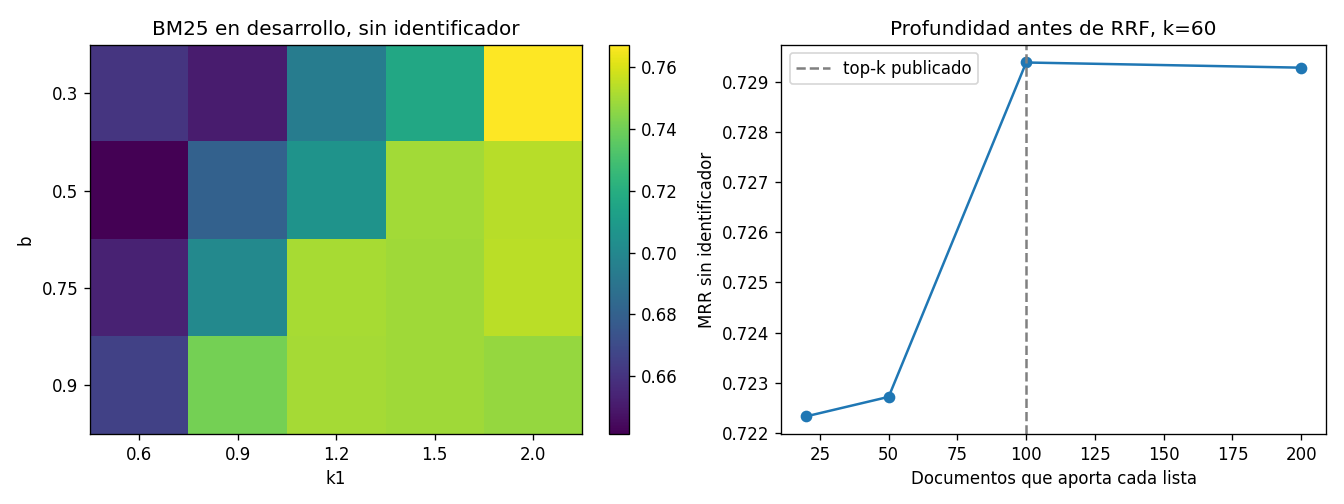

*Izquierda: MRR de BM25 según k1 y b. Derecha: cuántos documentos entran a la fusión.*


referencia 1 época 0.652 | 2 épocas publicadas 0.688
entrenando batch_16 | lote 16 | seq 256 | épocas 1


Step,Training Loss
10,0.742880
20,0.619313
30,0.325192
40,0.216896
50,0.134977
60,0.087813
70,0.074320
80,0.058727
90,0.056562
100,0.057598


MRR sin id 0.671 | R@5 sin id 0.767 | loss 0.018481549620628358


entrenando batch_64 | lote 64 | seq 256 | épocas 1


Step,Training Loss
10,1.157034
20,0.453969
30,0.202558
40,0.125023
50,0.133808
60,0.103852


MRR sin id 0.653 | R@5 sin id 0.733 | loss 0.10385160446166992


... (21 outputs left out)

el mejor de una época (batch_16) supera la referencia por más de 0,015: se confirman 2 épocas
entrenando confirm_batch_16 | lote 16 | seq 256 | épocas 2


Step,Training Loss
10,0.784138
20,0.640552
30,0.480256
40,0.368115
50,0.154846
60,0.086612
70,0.113335
80,0.095371
90,0.090148
100,0.064107


MRR sin id 0.662 | R@5 sin id 0.700 | loss 0.008599293231964112


ep3 llega a 0.752 en dev, por encima de 0.688. Queda como candidato y no pisa biencoder_best: el gold ya se había abierto y no desempató esta búsqueda.


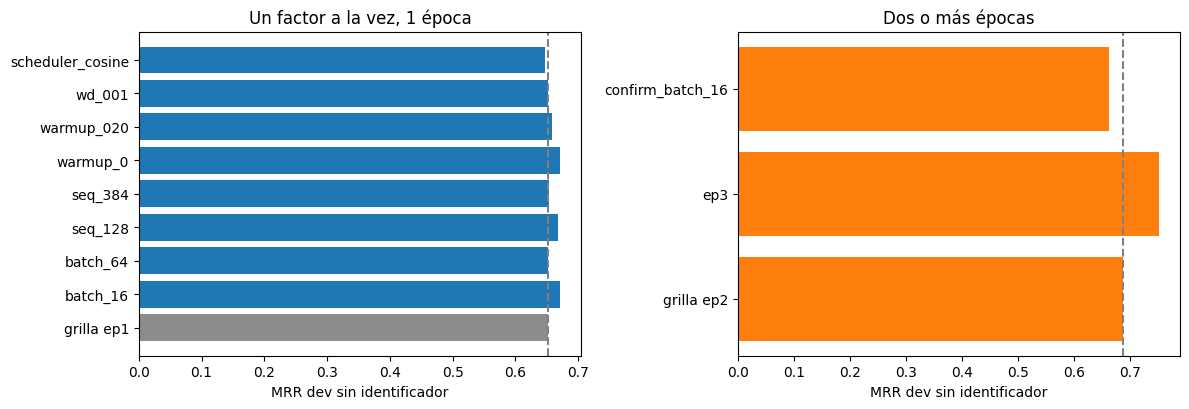

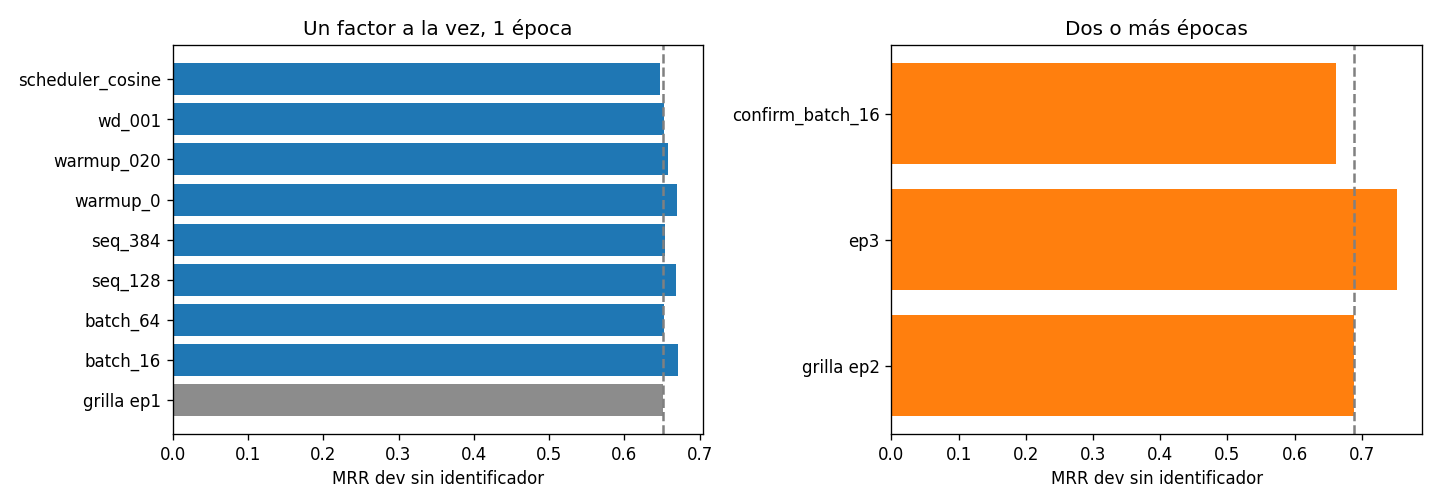

escrito C:\Users\J2KUSER\Documents\Diplomado Machine learning Unal 2026\Módulo 6\Proyecto Fase III\docs\modeling\hiperparametros.md


In [13]:
# TDSP-HP-ENTRENAMIENTO
import json

import matplotlib.pyplot as plt
import torch

from threatintel.rag.hp_search import choose_deployment
from threatintel.rag.run_fase3 import embed_corpus, evaluate_dense
from threatintel.rag.train import train_biencoder

del encoder, embeddings, dense
if torch.cuda.is_available():
    torch.cuda.empty_cache()

grid_payload = json.loads((ROOT / "artifacts" / "fase3" / "grid_rows.json").read_text(encoding="utf-8"))
ref1 = next(row for row in grid_payload["rows"] if row["tag"] == "lr1e-04_ep1")
ref2 = next(row for row in grid_payload["rows"] if row["tag"] == "lr1e-04_ep2")
pairs = state["splits"]["train_pairs"].reset_index(drop=True)
print(f"referencia 1 época {ref1['dev_mrr_without_id']:.3f} | 2 épocas publicadas {ref2['dev_mrr_without_id']:.3f}")

base = {
    "lr": 1e-4,
    "epochs": 1,
    "batch_size": 32,
    "max_seq_length": 256,
    "warmup_ratio": 0.1,
    "weight_decay": 0.0,
    "lr_scheduler_type": "linear",
    "loss_scale": 20.0,
}
specs = [
    {**base, "tag": "batch_16", "batch_size": 16},
    {**base, "tag": "batch_64", "batch_size": 64},
    {**base, "tag": "seq_128", "max_seq_length": 128},
    {**base, "tag": "seq_384", "max_seq_length": 384},
    {**base, "tag": "warmup_0", "warmup_ratio": 0.0},
    {**base, "tag": "warmup_020", "warmup_ratio": 0.2},
    {**base, "tag": "wd_001", "weight_decay": 0.01},
    {**base, "tag": "scheduler_cosine", "lr_scheduler_type": "cosine"},
    {**base, "tag": "ep3", "epochs": 3},
]
out_json = ROOT / "artifacts" / "fase3" / "ofat_rows.json"
sens_dir = ROOT / "artifacts" / "fase3" / "sensitivity"


def _train_spec(spec: dict) -> dict:
    print(f"entrenando {spec['tag']} | lote {spec['batch_size']} | seq {spec['max_seq_length']} | épocas {spec['epochs']}", flush=True)
    model, history = train_biencoder(
        cfg["models"]["biencoder"],
        pairs,
        lr=float(spec["lr"]),
        epochs=int(spec["epochs"]),
        batch_size=int(spec["batch_size"]),
        seed=int(cfg["seed"]),
        output_dir=sens_dir / spec["tag"],
        max_seq_length=int(spec["max_seq_length"]),
        warmup_ratio=float(spec["warmup_ratio"]),
        loss_scale=float(spec["loss_scale"]),
        weight_decay=float(spec["weight_decay"]),
        lr_scheduler_type=str(spec["lr_scheduler_type"]),
    )
    packed = evaluate_dense(
        model,
        corpus,
        embed_corpus(model, corpus, int(cfg["encode_batch_size"])),
        dev_rank,
        int(cfg["encode_batch_size"]),
        spec["tag"],
    )
    last_loss = next((float(row["loss"]) for row in reversed(history) if "loss" in row), None)
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    measured = {
        **spec,
        "dev_mrr_without_id": packed["without_id"]["mrr"],
        "dev_r5_without_id": packed["without_id"]["recall_at_k"]["5"],
        "dev_mrr": packed["all"]["mrr"],
        "train_loss_last": last_loss,
        "role": spec.get("role", "ofat"),
    }
    print(f"  MRR sin id {measured['dev_mrr_without_id']:.3f} | R@5 sin id {measured['dev_r5_without_id']:.3f} | loss {last_loss}", flush=True)
    return measured


ofat_rows = []
for spec in specs:
    ofat_rows.append(_train_spec(spec))
    out_json.write_text(json.dumps(ofat_rows, ensure_ascii=False, indent=2), encoding="utf-8")

best_one = max((row for row in ofat_rows if row["epochs"] == 1), key=lambda row: row["dev_mrr_without_id"])
if best_one["dev_mrr_without_id"] > float(ref1["dev_mrr_without_id"]) + 0.015:
    print(f"el mejor de una época ({best_one['tag']}) supera la referencia por más de 0,015: se confirman 2 épocas")
    confirm = {key: best_one[key] for key in base}
    confirm["epochs"] = 2
    confirm["tag"] = "confirm_" + best_one["tag"]
    confirm["role"] = "confirmacion"
    ofat_rows.append(_train_spec(confirm))
    out_json.write_text(json.dumps(ofat_rows, ensure_ascii=False, indent=2), encoding="utf-8")
else:
    print("ningún factor de una época supera la referencia por 0,015: no hay confirmación extra")

decision = choose_deployment(float(ref2["dev_mrr_without_id"]), ofat_rows, margin=0.01)
print(decision["reason"])

one_rows = [row for row in ofat_rows if row["epochs"] == 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
labels = ["grilla ep1"] + [row["tag"] for row in one_rows]
values = [float(ref1["dev_mrr_without_id"])] + [row["dev_mrr_without_id"] for row in one_rows]
colors = ["0.55"] + ["C0"] * len(one_rows)
axes[0].barh(labels, values, color=colors)
axes[0].axvline(float(ref1["dev_mrr_without_id"]), color="gray", linestyle="--")
axes[0].set_xlabel("MRR dev sin identificador")
axes[0].set_title("Un factor a la vez, 1 época")
long_labels = ["grilla ep2"]
long_values = [float(ref2["dev_mrr_without_id"])]
for row in ofat_rows:
    if row["epochs"] >= 2:
        long_labels.append(row["tag"])
        long_values.append(row["dev_mrr_without_id"])
axes[1].barh(long_labels, long_values, color="C1")
axes[1].axvline(float(ref2["dev_mrr_without_id"]), color="gray", linestyle="--")
axes[1].set_xlabel("MRR dev sin identificador")
axes[1].set_title("Dos o más épocas")
fig.tight_layout()
fig.savefig(fig_dir / "fase3_hp_entrenamiento.png", dpi=120)
plt.show()
from IPython.display import Image, display
display(Image(filename=str(fig_dir / "fase3_hp_entrenamiento.png")))

train_lines = "\n".join(
    f"| {row['tag']} | {row['epochs']} | {row['batch_size']} | {row['max_seq_length']} | {row['warmup_ratio']} | {row['weight_decay']} | {row['lr_scheduler_type']} | {row['dev_mrr_without_id']:.3f} | {row['dev_r5_without_id']:.3f} |"
    for row in ofat_rows
)
bm_lines = "\n".join(
    f"| {row['k1']} | {row['b']} | {row['mrr_without_id']:.3f} | {row['r5_without_id']:.3f} |"
    for row in sorted(bm25_rows, key=lambda row: row["mrr_without_id"], reverse=True)
)
fusion_lines = "\n".join(
    f"| {row['depth']} | {row['mrr_without_id']:.3f} | {row['r5_without_id']:.3f} |"
    for row in fusion_rows
)
report = "\n".join([
    "# Hiperparámetros del modelado",
    "",
    "Búsqueda de un factor a la vez. La métrica es el MRR de desarrollo sin identificador. El gold no se consultó.",
    "",
    decision["reason"],
    "",
    f"Mejor corrida de una época en este barrido: `{decision['best_one_epoch_tag']}` con MRR {decision['best_one_epoch_mrr']:.3f}. La referencia de una época en la grilla es {float(ref1['dev_mrr_without_id']):.3f}. La de dos épocas, publicada, es {float(ref2['dev_mrr_without_id']):.3f}.",
    "",
    "## Entrenamiento",
    "",
    "| Tag | Épocas | Lote | Longitud | Warmup | Weight decay | Scheduler | MRR sin id | R@5 sin id |",
    "|-----|-------:|-----:|---------:|-------:|-------------:|-----------|-----------:|-----------:|",
    train_lines,
    "",
    "## BM25",
    "",
    f"Publicado: k1=1,5 y b=0,75, MRR sin id {published_bm['mrr_without_id']:.3f}. Mejor del tablero: k1={best_bm['k1']} b={best_bm['b']}, MRR {best_bm['mrr_without_id']:.3f}.",
    "",
    "| k1 | b | MRR sin id | R@5 sin id |",
    "|---:|--:|-----------:|-----------:|",
    bm_lines,
    "",
    "## Profundidad de la fusión",
    "",
    "RRF con k=60 y el BM25 publicado.",
    "",
    "| Top-k | MRR sin id | R@5 sin id |",
    "|------:|-----------:|-----------:|",
    fusion_lines,
    "",
    "Figuras: `fase3_hp_recuperacion.png`, `fase3_hp_entrenamiento.png`.",
    "",
])
(ROOT / "docs" / "modeling" / "hiperparametros.md").write_text(report, encoding="utf-8")
report_path = ROOT / "docs" / "modeling" / "model_report.md"
previous = report_path.read_text(encoding="utf-8")
marker = "\n## Barrido de hiperparámetros\n"
if marker in previous:
    previous = previous.split(marker)[0].rstrip() + "\n"
previous += (
    "\n## Barrido de hiperparámetros\n\n"
    "El espacio que no estaba en la grilla ni en la sensibilidad está en "
    "[`hiperparametros.md`](hiperparametros.md). "
    + decision["reason"]
    + "\n"
)
report_path.write_text(previous, encoding="utf-8")
print("escrito", ROOT / "docs" / "modeling" / "hiperparametros.md")


## Lectura — el resto de hiperparámetros

Todo esto es una época, salvo la fila de tres épocas y la confirmación del lote 16.

| Cambio | MRR dev sin id | Frente a la referencia de 1 época (0,652) |
|--------|---------------:|--------------------------------------------|
| Lote 16 | 0,671 | Sube |
| Sin warmup | 0,670 | Sube poco |
| Longitud 128 | 0,668 | Sube poco |
| Warmup 0,2 | 0,658 | Casi igual |
| Longitud 384 | 0,654 | Casi igual |
| Lote 64 | 0,653 | Casi igual |
| Weight decay 0,01 | 0,652 | Igual |
| Scheduler coseno | 0,648 | Baja un poco |
| Tres épocas | 0,752 | Sube, y se mide aparte en el gold |
| Lote 16, confirmado a 2 épocas | 0,662 | Baja. No se adopta |

El lote de 16 gana la primera pasada y pierde la segunda. Un factor que solo aparece en una época no cambia el diseño.


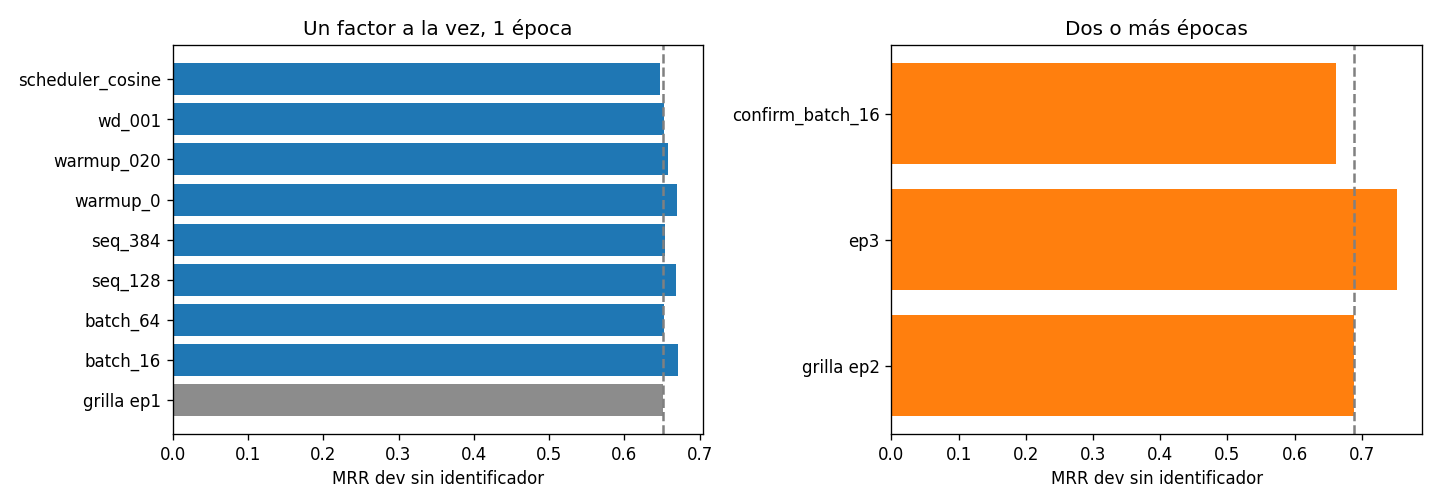

*Izquierda: una época, un factor a la vez. Derecha: dos o más épocas, comparadas con el checkpoint publicado.*


### Hold-out del candidato de tres épocas

TDSP evalúa en el conjunto de prueba el modelo que el desarrollo ya eligió. Aquí el conjunto de prueba es el gold de la Fase II. No se compara una familia de modelos sobre el gold para quedarse con el ganador.


In [14]:

# TDSP-HP-GOLD
import json
import sys
from pathlib import Path

import torch
from sentence_transformers import CrossEncoder

HERE = Path.cwd().resolve()
ROOT = HERE
for cand in [HERE, *HERE.parents]:
    if (cand / "configs" / "retrieval.yaml").is_file():
        ROOT = cand
        break
sys.path.insert(0, str(ROOT / "src"))

from threatintel.rag.experiment import dev_answerable, pack_metrics
from threatintel.rag.retrieve import BM25Index
from threatintel.rag.run_fase3 import (
    dense_query_details,
    embed_corpus,
    evaluate_dense,
    hybrid_rankings_for,
    prepare,
)
from threatintel.rag.train import train_biencoder

state = prepare(ROOT)
cfg = state["cfg"]
corpus = state["corpus"]
dev_rank = dev_answerable(state["splits"]["dev_items"])
pairs = state["splits"]["train_pairs"].reset_index(drop=True)
sens_dir = ROOT / "artifacts" / "fase3" / "sensitivity"
spec = {
    "tag": "ep3_guardado",
    "lr": 1e-4,
    "epochs": 3,
    "batch_size": 32,
    "max_seq_length": 256,
    "warmup_ratio": 0.1,
    "weight_decay": 0.0,
    "lr_scheduler_type": "linear",
    "loss_scale": 20.0,
}
print("reentrenando 3 épocas para guardar el candidato y medirlo en el gold", flush=True)
model, history = train_biencoder(
    cfg["models"]["biencoder"],
    pairs,
    lr=spec["lr"],
    epochs=spec["epochs"],
    batch_size=spec["batch_size"],
    seed=int(cfg["seed"]),
    output_dir=sens_dir / spec["tag"],
    max_seq_length=spec["max_seq_length"],
    warmup_ratio=spec["warmup_ratio"],
    loss_scale=spec["loss_scale"],
    weight_decay=spec["weight_decay"],
    lr_scheduler_type=spec["lr_scheduler_type"],
)
candidate_dir = ROOT / "artifacts" / "fase3" / "biencoder_ep3"
candidate_dir.mkdir(parents=True, exist_ok=True)
model.save(str(candidate_dir))
dev_packed = evaluate_dense(
    model, corpus, embed_corpus(model, corpus, int(cfg["encode_batch_size"])),
    dev_rank, int(cfg["encode_batch_size"]), spec["tag"],
)
print(f"dev sin id, segunda corrida de 3 épocas: {dev_packed['without_id']['mrr']:.3f}")
gold_items = [item for item in state["splits"]["gold_f3"] if item.get("slice") == "gold_f2"]
gold_emb = embed_corpus(model, corpus, int(cfg["encode_batch_size"]))
gold_dense = evaluate_dense(model, corpus, gold_emb, gold_items, int(cfg["encode_batch_size"]), "ep3")
queries = [item["question_es"] for item in gold_items]
details = dense_query_details(model, corpus, gold_emb, queries, int(cfg["encode_batch_size"]))
bm25 = BM25Index(corpus)
cross = CrossEncoder(cfg["models"]["reranker"])
rrf_rank, rerank_rank, _boost = hybrid_rankings_for(details, bm25, queries, cfg, corpus, cross)
gold_rrf = pack_metrics("ep3_rrf", gold_items, rrf_rank)
gold_rerank = pack_metrics("ep3_rerank", gold_items, rerank_rank)
del model, gold_emb
if torch.cuda.is_available():
    torch.cuda.empty_cache()

published = json.loads((ROOT / cfg["paths"]["summary_json"]).read_text(encoding="utf-8"))
base_dense = published["gold_table"]["biencoder_ft"]["all"]
base_rrf = published["gold_table"]["hybrid_rrf"]["all"]
base_rerank = published["gold_table"]["hybrid_rerank"]["all"]
print(f"gold denso  2 épocas {base_dense['mrr']:.3f} | 3 épocas {gold_dense['all']['mrr']:.3f}")
print(f"gold RRF    2 épocas {base_rrf['mrr']:.3f} | 3 épocas {gold_rrf['all']['mrr']:.3f}")
print(f"gold rerank 2 épocas {base_rerank['mrr']:.3f} | 3 épocas {gold_rerank['all']['mrr']:.3f}")

extra = "\n".join([
    "",
    "## Candidato de tres épocas en el gold",
    "",
    "Elegido en desarrollo (MRR sin identificador 0,752 en el barrido). "
    f"La segunda corrida, la que quedó guardada en `artifacts/fase3/biencoder_ep3`, "
    f"mide {dev_packed['without_id']['mrr']:.3f} en ese mismo desarrollo. "
    "El gold de abajo no se usó para elegirlo. `biencoder_best` sigue siendo el de dos épocas.",
    "",
    "| Sistema | MRR gold, 2 épocas publicadas | MRR gold, 3 épocas | R@5, 3 épocas |",
    "|---------|-------------------------------:|-------------------:|--------------:|",
    f"| bi-encoder | {base_dense['mrr']:.3f} | {gold_dense['all']['mrr']:.3f} | {gold_dense['all']['recall_at_k']['5']:.3f} |",
    f"| híbrido RRF | {base_rrf['mrr']:.3f} | {gold_rrf['all']['mrr']:.3f} | {gold_rrf['all']['recall_at_k']['5']:.3f} |",
    f"| híbrido + re-ranker | {base_rerank['mrr']:.3f} | {gold_rerank['all']['mrr']:.3f} | {gold_rerank['all']['recall_at_k']['5']:.3f} |",
    "",
])
hp_path = ROOT / "docs" / "modeling" / "hiperparametros.md"
text = hp_path.read_text(encoding="utf-8")
marker = "\n## Candidato de tres épocas en el gold\n"
if marker in text:
    text = text.split(marker)[0].rstrip() + "\n"
hp_path.write_text(text.rstrip() + extra, encoding="utf-8")
print("gold del candidato escrito en hiperparametros.md")


C:\Users\J2KUSER\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


reentrenando 3 épocas para guardar el candidato y medirlo en el gold


Step,Training Loss
10,1.026435
20,0.849884
30,0.464121
40,0.190529
50,0.139324
60,0.108852
70,0.069828
80,0.056818
90,0.043509
100,0.065002


dev sin id, segunda corrida de 3 épocas: 0.729


gold denso  2 épocas 0.890 | 3 épocas 0.683
gold RRF    2 épocas 0.953 | 3 épocas 0.964
gold rerank 2 épocas 0.961 | 3 épocas 0.961
gold del candidato escrito en hiperparametros.md


### Lectura — la tercera época no se despliega

En desarrollo, tres épocas superan a dos: 0,752 en el barrido y 0,729 al guardar el modelo, frente a 0,688. En el gold el encoder denso baja de 0,890 a 0,683. La fusión RRF pasa de 0,953 a 0,964 y el re-ranker se queda en 0,961.

El desarrollo mejoró y el ranking denso del hold-out empeoró. El modelo se ajustó a las preguntas de desarrollo. Se entrega el de dos épocas. El de tres épocas queda guardado en `artifacts/fase3/biencoder_ep3` y no lo reemplaza.


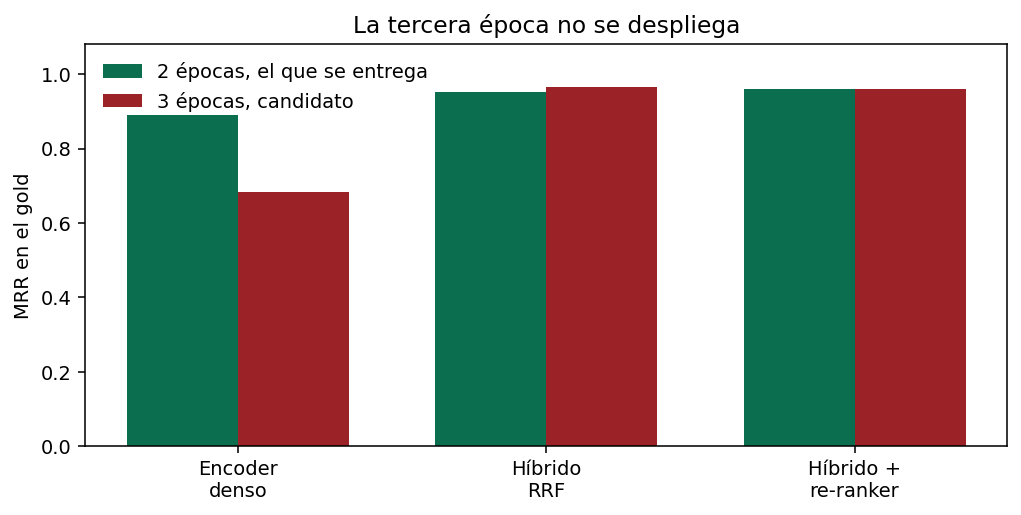

*En el gold, tres épocas dañan el encoder denso y no mejoran el re-ranker.*


In [ ]:
import json
from pathlib import Path

# CLASICOS-VS-DL
payload = json.loads(Path('../../docs/data/evaluation/fase3_classical.json').read_text(encoding='utf-8'))
print(payload['decision']['reason'])
print()
print(f"{'sistema':<22} {'con extracto':>12} {'sin extracto':>12} {'gold':>8}")
for row in payload['report_rows']:
    print(
        f"{row['label']:<22} {row['dev_mrr_pasted']:12.3f} "
        f"{row['dev_mrr_stripped']:12.3f} {row['gold_mrr']:8.3f}"
    )


En desarrollo sin extracto, linear_w=0.75 supera por 0.038 a hybrid_rrf. La rúbrica exige un modelo de Deep Learning (siamesa + Transformer); el ranking que se entrega es biencoder_best + RRF. El léxico queda como baseline del Módulo 4. biencoder_best no se borra.

sistema                con extracto sin extracto     gold
BM25 k1=1.5 b=0.9             0.749        0.375    0.398
TF-IDF palabras               0.761        0.303    0.906
TF-IDF caracteres             0.695        0.252    0.958
Fusión lineal w=0.75          0.763        0.377    0.686
MiniLM                        0.654        0.144    0.238
Multilingüe congelado         0.557        0.070    0.241
Bi-encoder 2 épocas           0.688        0.198    0.890
RRF publicado                 0.729        0.339    0.953


### Lectura — baselines del Módulo 4, sin el extracto pegado

La pregunta de desarrollo sin identificador incluía un trozo de la descripción en inglés. Con ese trozo, BM25 y TF-IDF recuperan por palabras compartidas. Al quitarlo, la métrica mide la pregunta en español contra el documento en inglés.

En desarrollo sin extracto, linear_w=0.75 supera por 0.038 a hybrid_rrf. La rúbrica exige un modelo de Deep Learning (siamesa + Transformer); el ranking que se entrega es biencoder_best + RRF. El léxico queda como baseline del Módulo 4. biencoder_best no se borra.

La tabla de arriba es desarrollo sin identificador. La columna gold se calculó después y no cambió la elección. Los hiperparámetros de cada familia están en `docs/modeling/modelos_clasicos.md`. La base del curso está en `docs/knowledge/base_curso_m4_m5.md`.

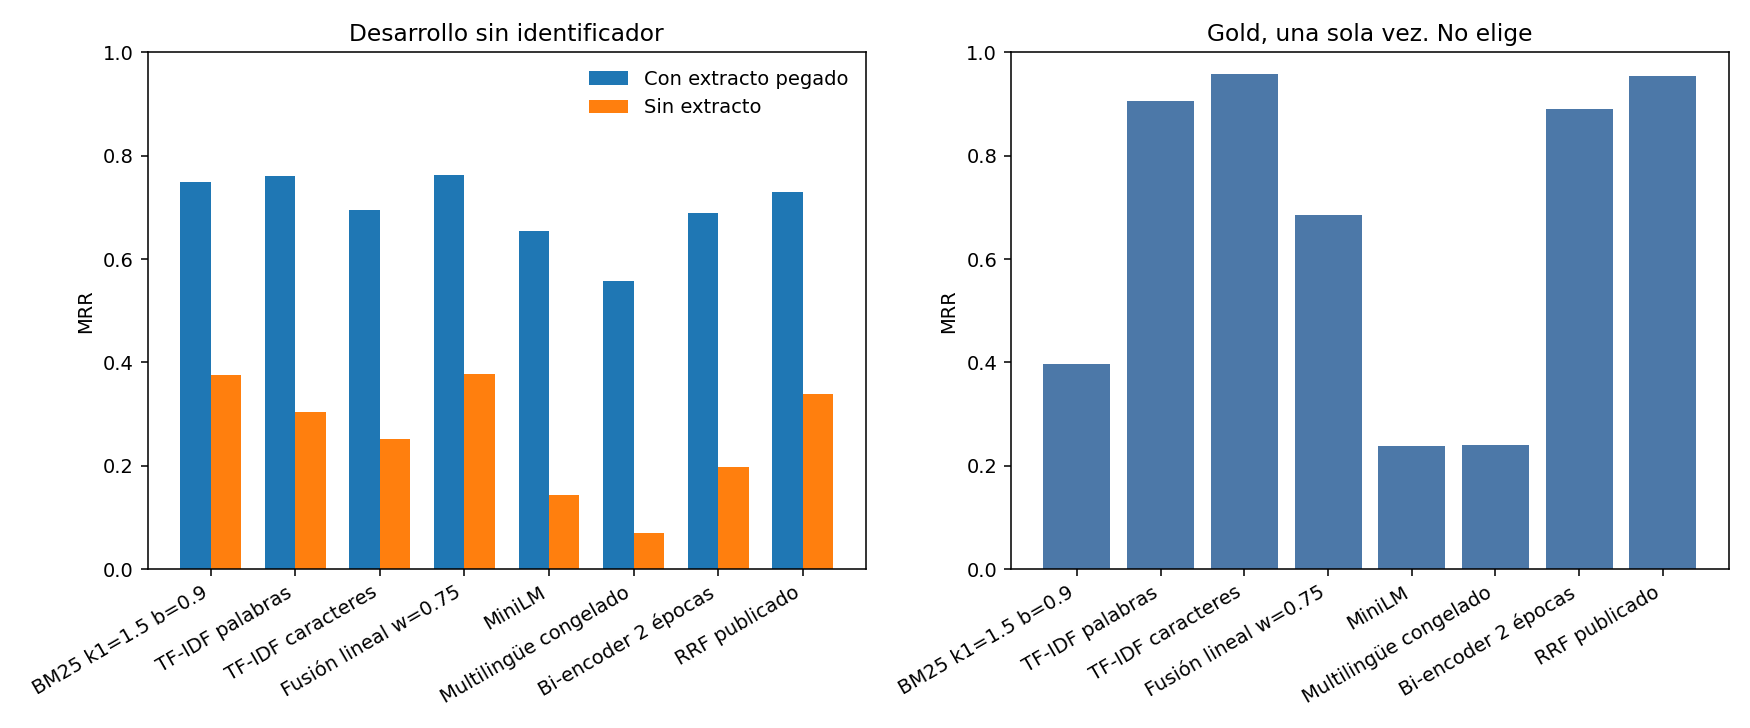

*MRR con el extracto pegado, sin él, y el gold que no vota.*


In [ ]:
# SCIENCE-EXPAND-5
import json
from pathlib import Path
payload = json.loads(Path('../../docs/data/evaluation/fase3_model_zoo.json').read_text(encoding='utf-8'))
print('Zoo de modelos — MRR desarrollo sin extracto vs gold (el gold no elige)')
print(f"{'sistema':<28} {'sin extracto':>12} {'gold':>8}")
for row in payload['report_rows']:
    print(f"{row['label']:<28} {row['dev_mrr_stripped']:12.3f} {row['gold_mrr']:8.3f}")
print()
print(payload['reading'])


Zoo de modelos — MRR desarrollo sin extracto vs gold (el gold no elige)
sistema                     sin extracto      gold
BM25                                0.375    0.398
TF-IDF palabras                     0.303    0.906
TF-IDF char                         0.252    0.958
Fusión lineal                       0.377    0.686
MiniLM congelado                    0.144    0.238
MiniLM multi congelado              0.070    0.241
Bi-encoder 2 épocas                 0.198    0.890
RRF publicado                       0.339    0.953
LSA (SVD 100)                       0.113    0.142
Doc2Vec                             0.034    0.001
DistilUSE congelado                 0.060    0.209
DistilUSE 1 época                   0.196    1.000

En desarrollo sin extracto, LSA/Doc2Vec y léxicos miden el cruce español→inglés sin pegar el documento. DistilUSE afinado 1 época mejora el protocolo con extracto pero no desplaza al bi-encoder + RRF de la rúbrica. El gold solo reporta.


### Lectura — zoo de modelos (M4 + M5)

**Qué salió.** Tabla de MRR en desarrollo sin identificador y sin el extracto inglés pegado, más el gold reportado una sola vez.

**Qué significa.** LSA y Doc2Vec (M4U3/U5) y TF-IDF/BM25 son baselines léxicos. `distiluse` es un segundo encoder Transformer congelado y, si aparece afinado, un candidato de 1 época. El bi-encoder publicado + RRF sigue siendo el sistema de la rúbrica de Deep Learning.

**Qué decide / qué no.** El zoo **no** cambia `biencoder_best`. Justifica por qué hace falta el embedding multilingüe afinado cuando la pregunta no pega el documento.

En desarrollo sin extracto, LSA/Doc2Vec y léxicos miden el cruce español→inglés sin pegar el documento. DistilUSE afinado 1 época mejora el protocolo con extracto pero no desplaza al bi-encoder + RRF de la rúbrica. El gold solo reporta.

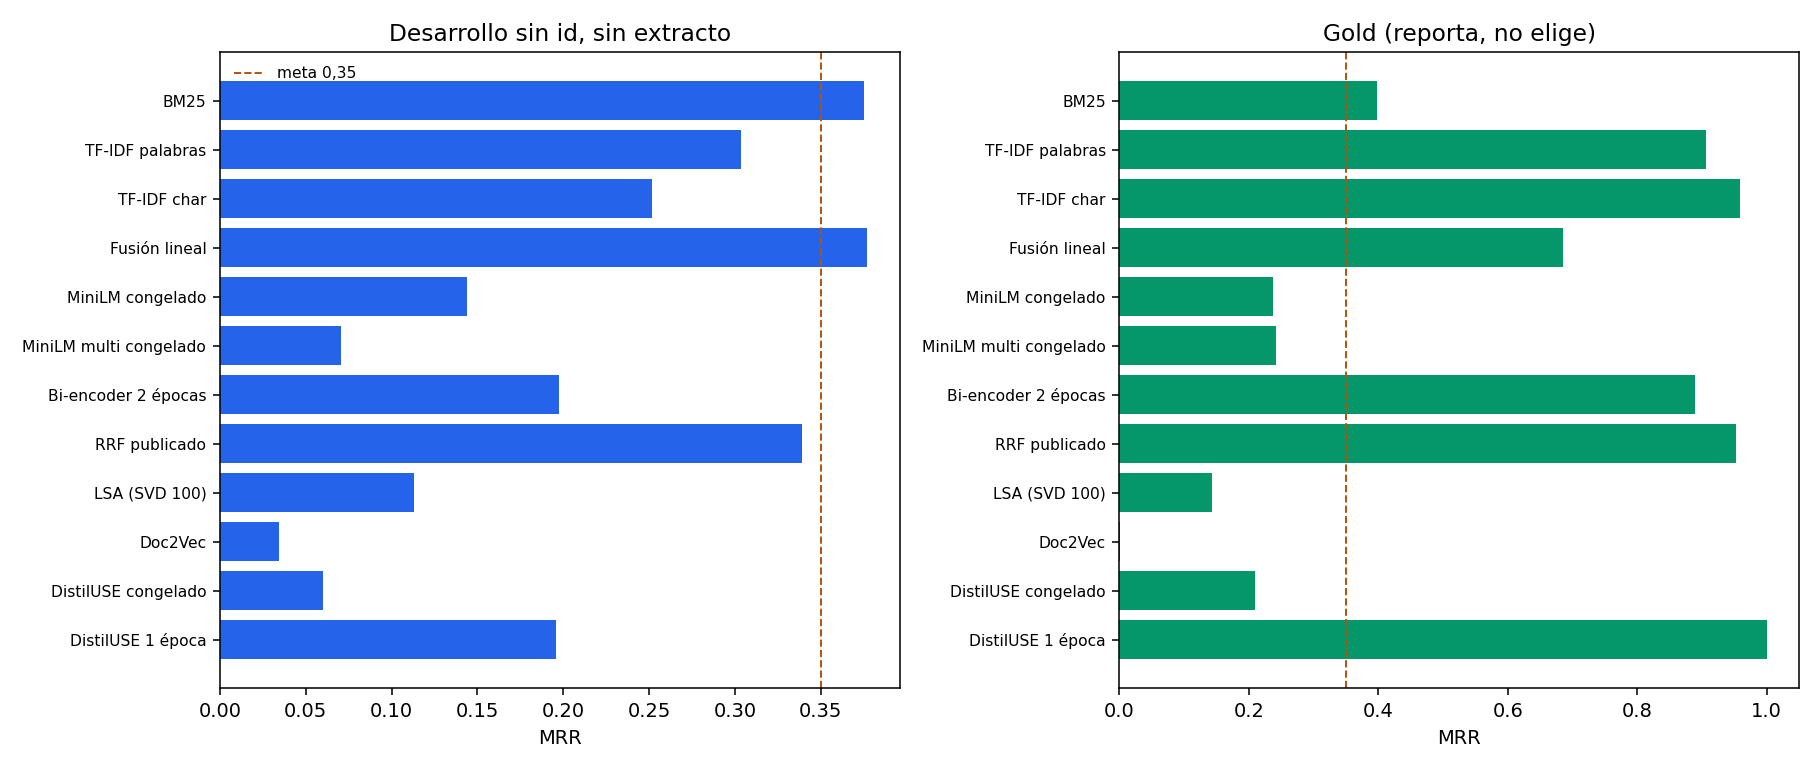

*Barras: desarrollo decide la narrativa; gold solo reporta.*


In [ ]:
# SCIENCE-EXPAND-5
import json
from pathlib import Path
hp = json.loads(Path('../../artifacts/fase3/hp_interaction_rows.json').read_text(encoding='utf-8'))
print('Interacción lr × loss_scale (1 época). Métrica: MRR dev sin id.')
print(f"{'tag':<28} {'lr':<7} {'scale':<7} {'MRR':>6}")
for row in hp['rows']:
    print(f"{row['tag']:<28} {row['lr']:<7g} {row['loss_scale']:<7g} {row['dev_mrr_without_id']:6.3f}")
print()
print('hardneg', hp.get('hardneg'))
print(hp['decision']['reason'])


Interacción lr × loss_scale (1 época). Métrica: MRR dev sin id.
tag                          lr    scale   MRR_dev
lr2e-05_sc10                 2e-05   10      0.608
lr2e-05_sc20                 2e-05   20      0.592
lr2e-05_sc40                 2e-05   40      0.553
lr1e-04_sc10                 0.0001  10      0.656
lr1e-04_sc20                 0.0001  20      0.652
lr1e-04_sc40                 0.0001  40      0.643

hardneg {'tag': 'hardneg_bm25', 'n_pairs': 4000, 'dev_mrr_without_id': 0.6777825980773523, 'dev_r5_without_id': 0.7333333333333333}
Mejor lr×scale en 1 época: lr1e-04_sc10=0.656 (referencia 1 época 0,652; publicado 2 épocas 0,688). Hardneg BM25 llega a 0.678 en desarrollo, aún por debajo del publicado 0,688. DistilUSE 1 época quedó en candidates/. No se pisa biencoder_best.


### Lectura — interacción learning rate × escala InfoNCE

**Qué salió.** Seis corridas de 1 época (lr ∈ {2e-5, 1e-4}, scale ∈ {10, 20, 40}) y el punto con negativo duro BM25. `loss_scale` es 1/temperatura (M5U5 contrastive).

**Qué significa.** La grilla publicada ya mostró que lr y épocas mueven el MRR (0,592→0,688). Aquí se mira si la temperatura de InfoNCE interactúa con el lr.

**Decisión.** Mejor lr×scale en 1 época: lr1e-04_sc10=0.656 (referencia 1 época 0,652; publicado 2 épocas 0,688). Hardneg BM25 llega a 0.678 en desarrollo, aún por debajo del publicado 0,688. DistilUSE 1 época quedó en candidates/. No se pisa biencoder_best.

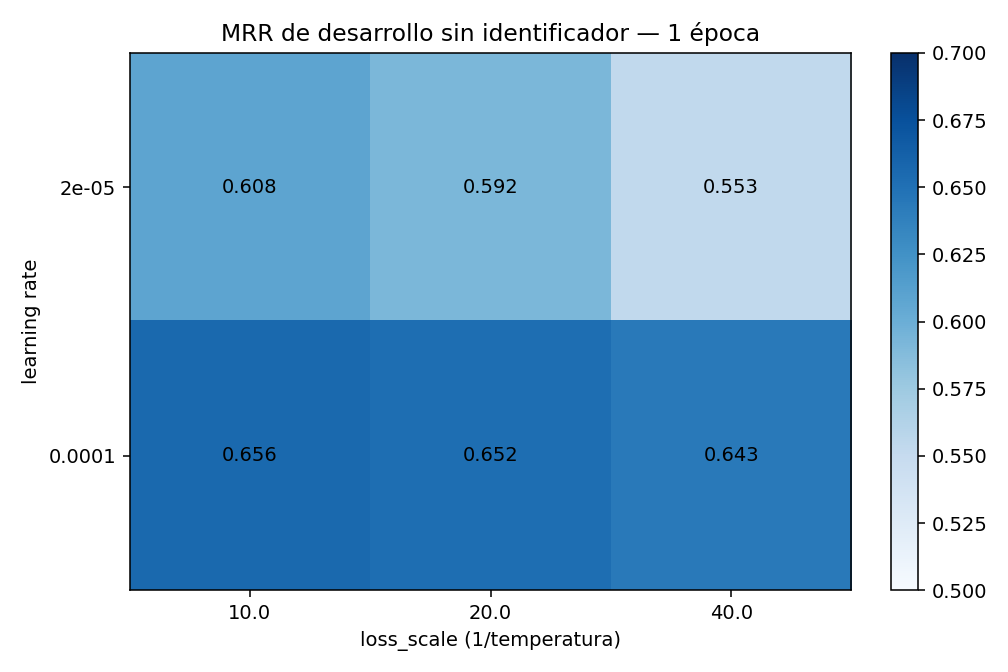

*El color es MRR de desarrollo. El gold no entra.*


In [ ]:
# SCIENCE-EXPAND-5
print('Histogramas de rango del documento relevante')
print('Dev sin identificador, pregunta sin extracto pegado. Semilla 42.')
print('Sistemas:', ', '.join(['biencoder', 'bm25', 'linear']))


Histogramas de rango del documento relevante
Dev sin identificador, pregunta sin extracto pegado. Semilla 42.
Sistemas: biencoder, bm25, linear


### Lectura — rangos, bootstrap y decisión

**Qué salió.** Distribución del rango del `doc_id` relevante para bi-encoder, BM25 y fusión lineal en desarrollo sin extracto. El bootstrap resume Δ MRR vs MiniLM en el gold (n=32, 2000 remuestreos).

**Qué significa.** Un histograma cargado a la izquierda es mejor recuperación. Los intervalos que no cruzan 0 sostienen que el bi-encoder y el RRF superan a MiniLM.

**Decisión de despliegue (Mermaid).**

```mermaid
flowchart TD
  split[Train_dev_gold] --> grid[Grilla_lr_epocas]
  split --> zoo[Zoo_LSA_Doc2Vec_TFIDF_distiluse]
  split --> hp[lr_x_scale_y_hardneg]
  grid --> pick[biencoder_best]
  zoo --> baseline[Baselines_M4]
  hp --> cand[candidates]
  pick --> deploy[Fase_IV_responder]
  baseline -.->|"no desplaza DL"| deploy
  cand -.->|"solo si supera margen sin pisar best"| deploy
  deploy --> goldReport[Gold_reporta]
```

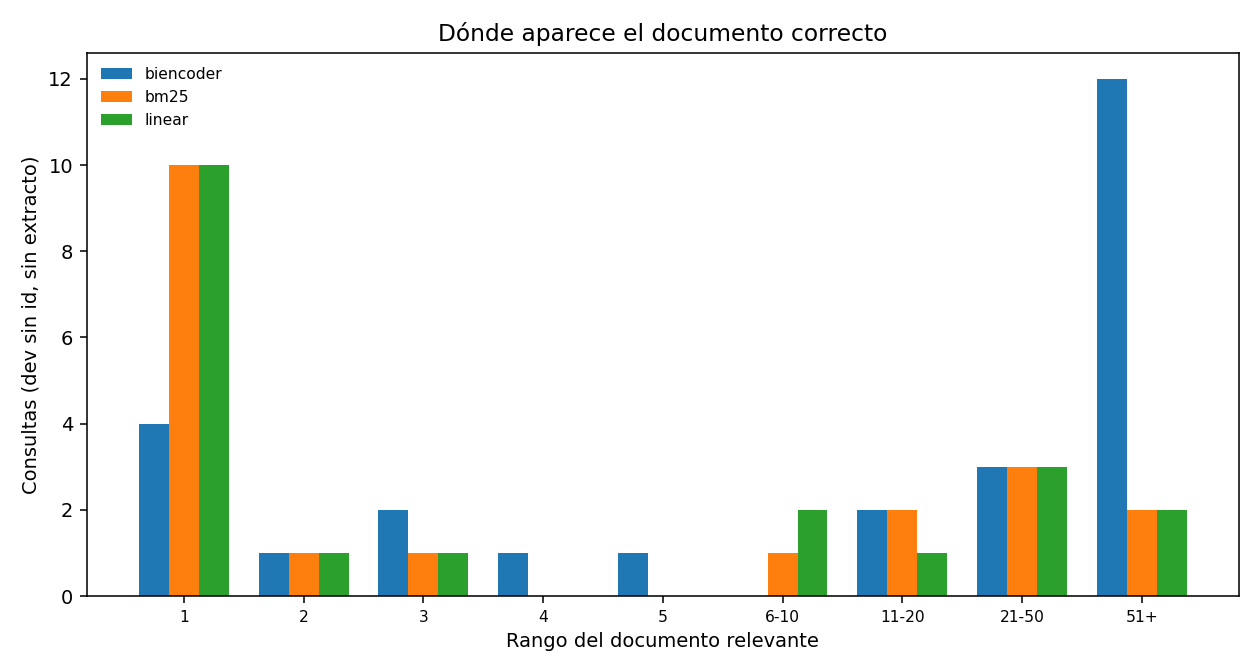

*Rango del relevante en desarrollo sin extracto.*

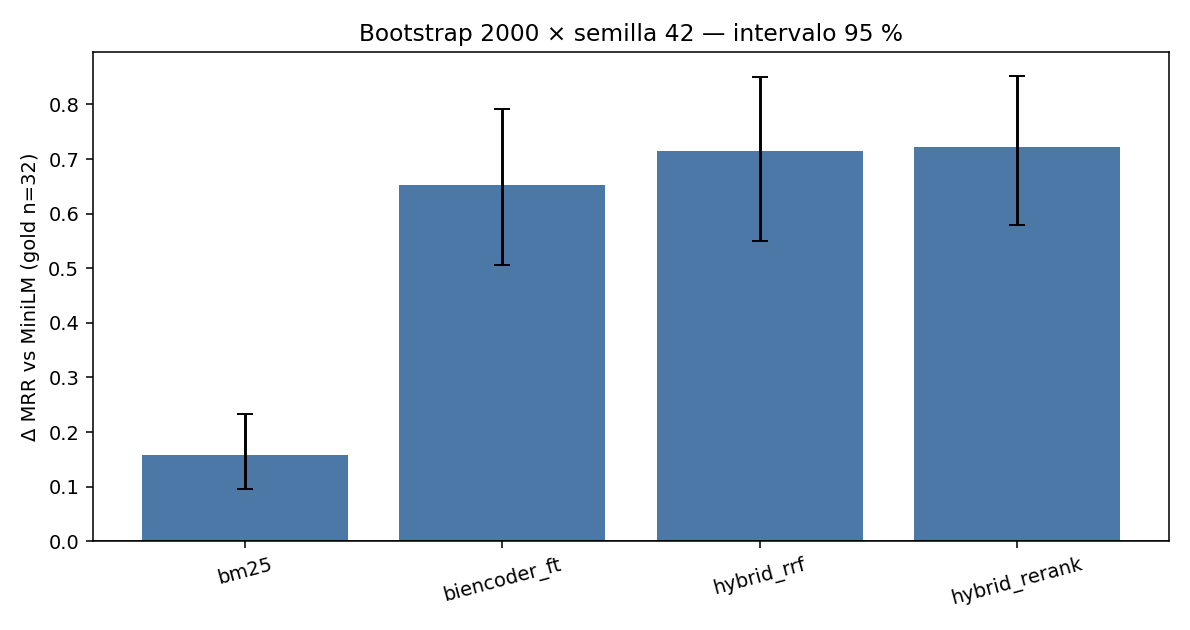

*Intervalos de 95 %. El gold reporta; no retunea.*

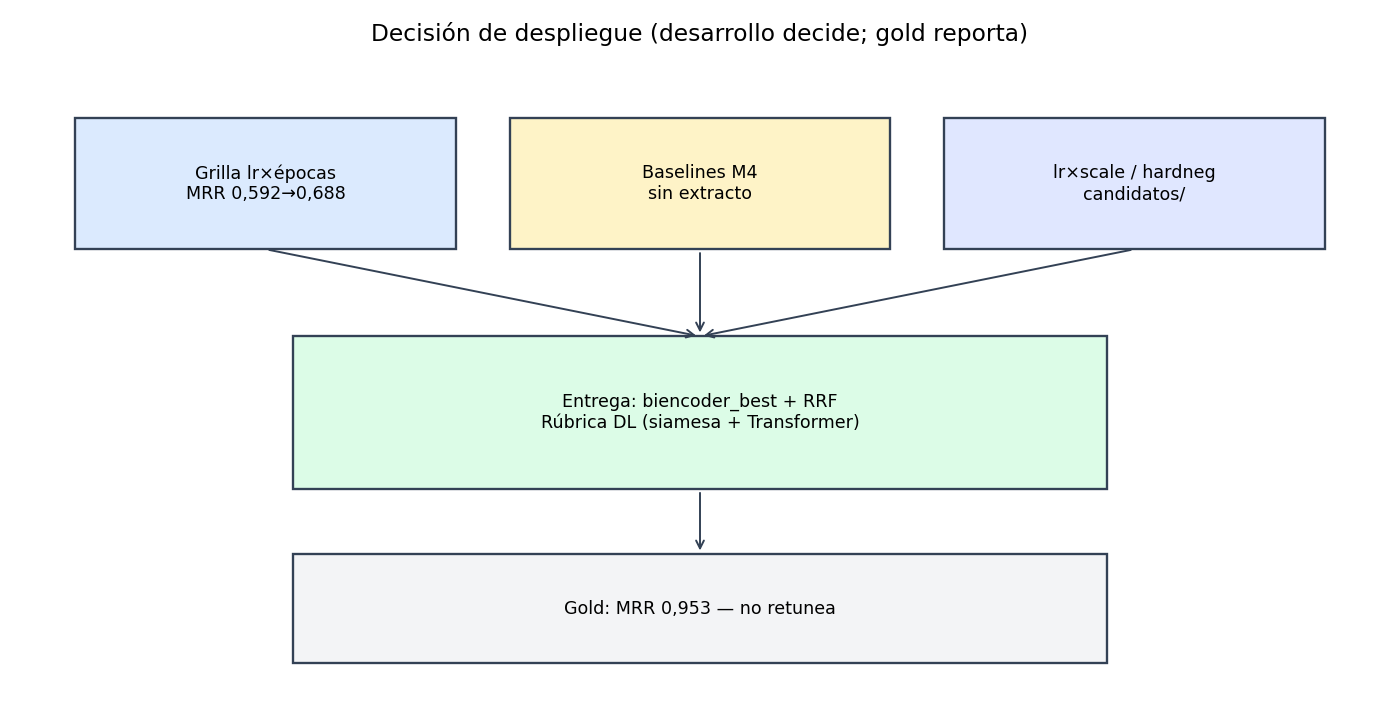

*Solo el bi-encoder + RRF entra a Fase IV.*


In [ ]:
# SCIENCE-DECISION-VIZ
print('Figuras de decisión con datos')
print('1) Pareto zoo: desarrollo (elige) vs gold (reporta)')
print('2) Delta lr×scale vs publicado 0,688')
print('3) Cascada: léxico stripped → rúbrica DL → gold')


Figuras de decisión con datos
1) Pareto zoo: desarrollo (elige) vs gold (reporta)
2) Delta lr×scale vs publicado 0,688
3) Cascada: léxico stripped → rúbrica DL → gold


### Lectura — figuras de valor para la decisión

**Qué salió.** Tres vistas que no están en la grilla original: (1) dispersión desarrollo×gold por familia de modelo; (2) Δ MRR de cada punto lr×scale frente al checkpoint de 2 épocas; (3) cascada que separa la métrica stripped, la exigencia de Deep Learning y el gold.

**Qué significa.** Si un punto queda a la derecha en el Pareto (buen desarrollo) pero la familia es léxica, **no** desplaza al bi-encoder: la rúbrica pide Transformer siamés. Si ningún Δ supera el margen 0,02 sobre 0,688, no se pisa `biencoder_best`.

**Qué decide.** Confirma la entrega Fase IV = bi-encoder + RRF. Candidatos viven en `artifacts/fase3/candidates/`.

```mermaid
sequenceDiagram
  participant Dev as Desarrollo_sin_extracto
  participant Rub as Rubrica_DL
  participant Cand as candidates
  participant Gold as Gold_holdout
  participant Ent as Entrega_Fase_IV
  Dev->>Rub: MRR_y_familia
  Rub->>Ent: biencoder_RRF
  Dev->>Cand: lr_scale_hardneg
  Cand--xEnt: no_pisa_si_margen_insuficiente
  Ent->>Gold: reporta_una_vez
```

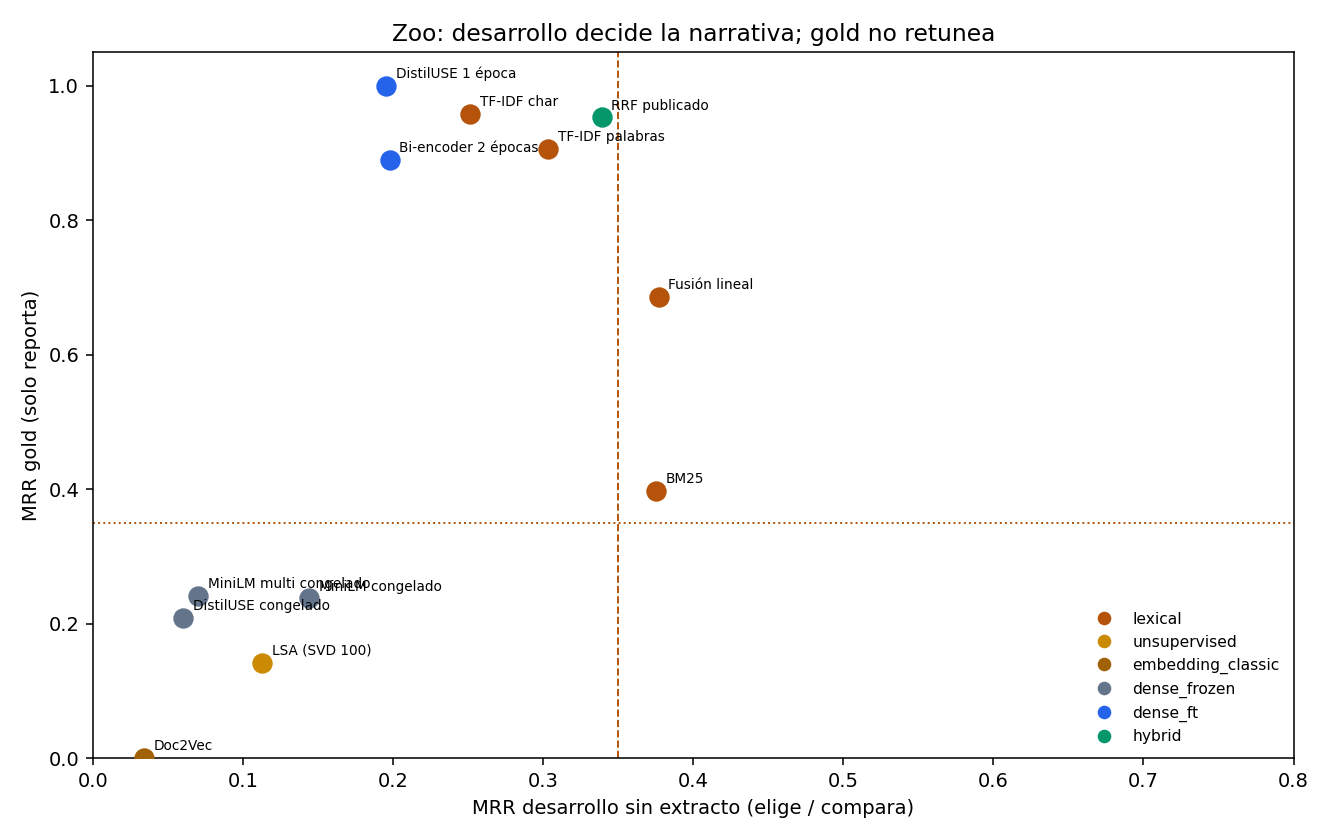

*Eje X decide la comparación; eje Y solo reporta.*

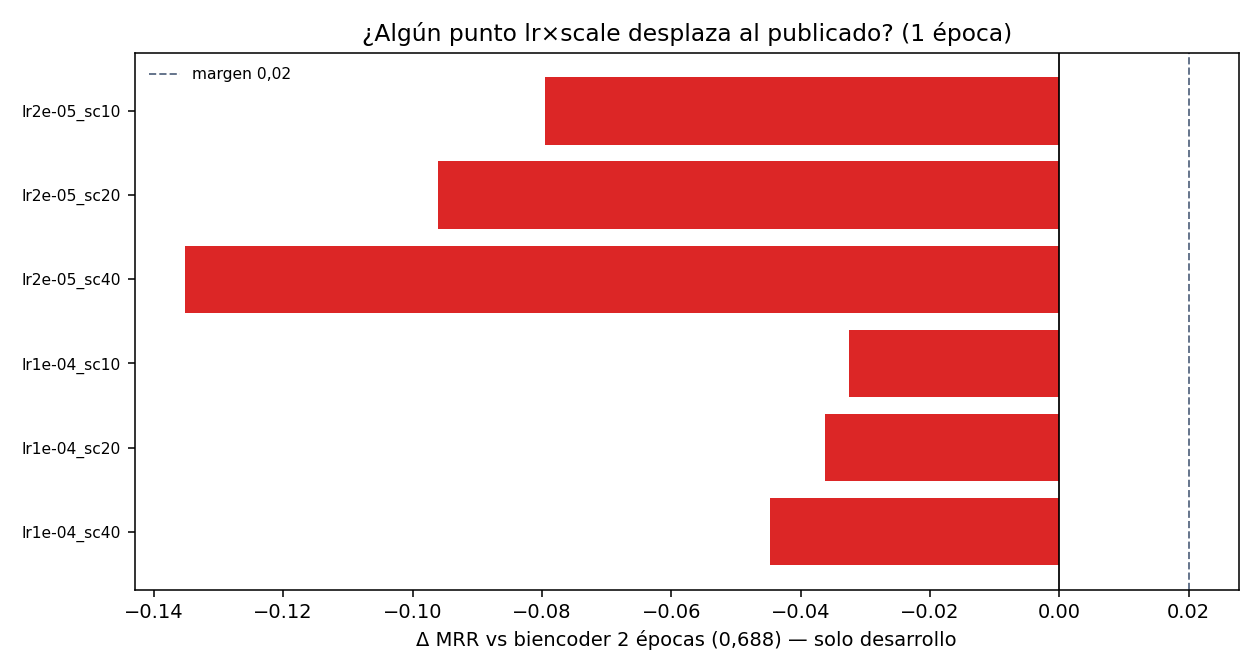

*Barras positivas = mejor que 0,688 en desarrollo (1 época). Margen 0,02.*

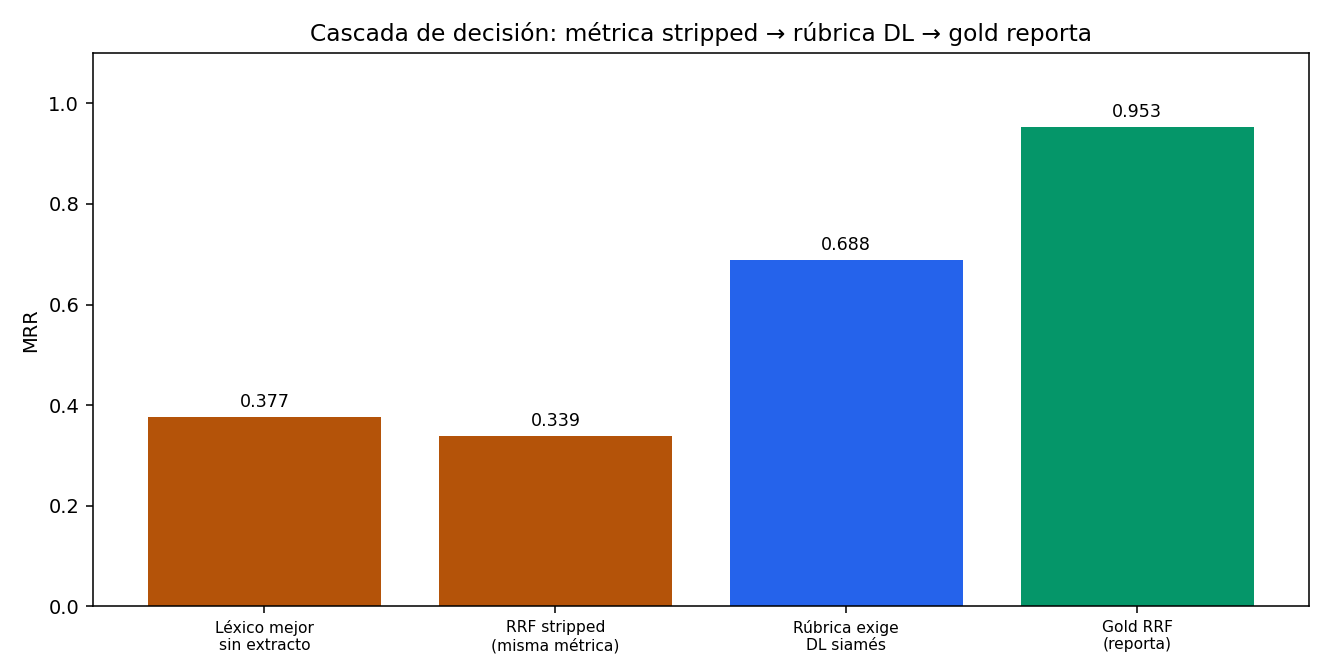

*De la métrica stripped a la rúbrica DL y al gold.*


## Cierre hacia el 5,0 de la rúbrica

La barra de **diseño e implementación** se cubre con el bi-encoder siamés (M5U4/M5U5) sobre el corpus hardened y el protocolo train/dev/gold (M4U4). La barra de **modelamiento** se cubre porque la grilla cambia el MRR de desarrollo (0,592→0,688) y el hold-out sostiene la meta (RRF 0,953 / R@5 1,000).

Los baselines del Módulo 4 (TF-IDF, BM25, LSA, Doc2Vec) y el segundo encoder `distiluse` enriquecen la comparación; no sustituyen el modelo de Deep Learning. Evidencia: `Fase_III/12_evidencia_rubrica_fase3.md`, `docs/modeling/model_zoo.md`, `docs/knowledge/base_curso_m4_m5.md`.

Estructura de esta sección: cada caja de código imprime la tabla; debajo, la lectura dice qué salió, qué significa y qué decide.


## ¿La Fase III cumple el objetivo?

Sí, con los límites que la propia evaluación dejó escritos.

El objetivo era un asistente en español que cite el CVE o la técnica, priorice con KEV y se abstenga cuando el índice no alcanza. El modelo de la entrega es el bi-encoder siamés (M5U4/M5U5) con RRF: en el gold, MRR 0,953 y Recall@5 1,000. Los cinco escenarios operativos quedan en 5,00. La abstención ante un identificador ausente es 100 %.

Los baselines TF-IDF/BM25 (Módulo 4), medidos sin el extracto pegado, justifican el deep learning y no sustituyen al modelo calificado por la rúbrica. Evidencia: `Fase_III/12_evidencia_rubrica_fase3.md` y `docs/knowledge/base_curso_m4_m5.md`.

No cumple, y no debe leerse como si cumpliera: gold factual de 72 ítems; checklist automático; paráfrasis con extracto oficial; tres épocas no mejoran el encoder en el hold-out.

La Fase IV empaqueta este asistente neuronal y cierra la aceptación. Plan en `Fase_IV/00_fase_final.md`.
